In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'ITUB4.SA'
papeis_adicionais = ['BBAS3.SA', 'BBDC4.SA', 'SANB11.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
#df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[ITUB4.SA] Cache existente cobre de 2020-01-02 a 2025-09-15.
[ITUB4.SA] Cache NÃO cobre período solicitado. Download total necessário.
[ITUB4.SA] Iniciando download de dados (lógica de atualização/complemento)...
[ITUB4.SA] Período de download yfinance: 2020-01-01 a 2025-09-21
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[ITUB4.SA] Realizando verificação de divergência entre cache antigo e dados frescos...
[ITUB4.SA] Pós-Download Total: Nenhuma divergência significativa nas amostras (tolerância 1.00%).
[ITUB4.SA] Cache principal ATUALIZADO com dados frescos: /palpiteiro/dados\ITUB4.csv
[ITUB4.SA] Retornando 614 linhas para o período solicitado.
⬇️ Baixando dados macro de 31/03/2022 a 17/09/2025...
Baixando série 432 (selic)...
Baixando série 433 (ipca)...
Baixando série 1 (dolar)...
💾 Dados salvos em cache: /palpiteiro/dados\macro_20220331_20250917.csv
[^BVSP] Cache existente cobre de 2020

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,mm200_close,close_norm_mm200,macd,macd_signal,macd_hist,ADX_14,DMP_14,DMN_14,BBL_20_2.0,BBM_20_2.0,BBU_20_2.0,BBB_20_2.0,BBP_20_2.0,atr_5,atr_50,obv,vwap,cmf,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov,adc_open_BBAS3,adc_high_BBAS3,adc_low_BBAS3,adc_close_BBAS3,adc_adj_close_BBAS3,adc_volume_BBAS3,adc_pct_change_BBAS3,adc_vol_BBAS3,adc_rsi_BBAS3,adc_mm200_close_BBAS3,adc_close_norm_mm200_BBAS3,adc_macd_BBAS3,adc_macd_signal_BBAS3,adc_macd_hist_BBAS3,adc_ADX_14_BBAS3,adc_DMP_14_BBAS3,adc_DMN_14_BBAS3,adc_BBL_20_2.0_BBAS3,adc_BBM_20_2.0_BBAS3,adc_BBU_20_2.0_BBAS3,adc_BBB_20_2.0_BBAS3,adc_BBP_20_2.0_BBAS3,adc_atr_5_BBAS3,adc_atr_50_BBAS3,adc_obv_BBAS3,adc_vwap_BBAS3,adc_cmf_BBAS3,adc_tr_BBAS3,adc_atr_BBAS3,adc_atr_pct_BBAS3,adc_tr_pct_BBAS3,adc_mm5_BBAS3,adc_mm20_BBAS3,adc_open_BBDC4,adc_high_BBDC4,adc_low_BBDC4,adc_close_BBDC4,adc_adj_close_BBDC4,adc_volume_BBDC4,adc_pct_change_BBDC4,adc_vol_BBDC4,adc_rsi_BBDC4,adc_mm200_close_BBDC4,adc_close_norm_mm200_BBDC4,adc_macd_BBDC4,adc_macd_signal_BBDC4,adc_macd_hist_BBDC4,adc_ADX_14_BBDC4,adc_DMP_14_BBDC4,adc_DMN_14_BBDC4,adc_BBL_20_2.0_BBDC4,adc_BBM_20_2.0_BBDC4,adc_BBU_20_2.0_BBDC4,adc_BBB_20_2.0_BBDC4,adc_BBP_20_2.0_BBDC4,adc_atr_5_BBDC4,adc_atr_50_BBDC4,adc_obv_BBDC4,adc_vwap_BBDC4,adc_cmf_BBDC4,adc_tr_BBDC4,adc_atr_BBDC4,adc_atr_pct_BBDC4,adc_tr_pct_BBDC4,adc_mm5_BBDC4,adc_mm20_BBDC4,adc_open_SANB11,adc_high_SANB11,adc_low_SANB11,adc_close_SANB11,adc_adj_close_SANB11,adc_volume_SANB11,adc_pct_change_SANB11,adc_vol_SANB11,adc_rsi_SANB11,adc_mm200_close_SANB11,adc_close_norm_mm200_SANB11,adc_macd_SANB11,adc_macd_signal_SANB11,adc_macd_hist_SANB11,adc_ADX_14_SANB11,adc_DMP_14_SANB11,adc_DMN_14_SANB11,adc_BBL_20_2.0_SANB11,adc_BBM_20_2.0_SANB11,adc_BBU_20_2.0_SANB11,adc_BBB_20_2.0_SANB11,adc_BBP_20_2.0_SANB11,adc_atr_5_SANB11,adc_atr_50_SANB11,adc_obv_SANB11,adc_vwap_SANB11,adc_cmf_SANB11,adc_tr_SANB11,adc_atr_SANB11,adc_atr_pct_SANB11,adc_tr_pct_SANB11,adc_mm5_SANB11,adc_mm20_SANB11
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-09-02,38.150002,38.480000,37.959999,38.119999,38.119999,23649200,-0.017019,0.013684,59.302292,33.196659,1.148308,0.564610,0.438718,0.125892,21.727452,33.549135,21.741560,35.901681,37.3820,38.862318,7.919952,0.749271,0.735920,0.712187,935874240.0,38.186666,0.043071,0.820000,0.746663,0.019587,0.021511,38.262,37.3820,15.0,-0.11,5.4680,141279.0,141279.0,139625.0,140335.0,140335.0,5174520,20.139999,20.670000,20.080000,20.420000,20.420000,46246800,-0.031769,0.022235,50.945961,24.76220,0.824644,0.181655,0.019504,0.162151,28.823345,26.383729,21.250929,18.426373,20.0295,21.632627,16.007662,0.621793,0.703400,0.594547,122344900.0,20.390000,0.240559,1.010000,0.666897,0.032659,0.049461,20.916,20.0295,16.459999,16.590000,16.280001,16.510000,16.510000,25223800,-0.012560,0.013539,57.337408,13.84490,1.192497,0.196344,0.126822,0.069522,25.503050,28.172845,19.189103,15.500759,16.1890,16.877241,8.502580,0.733203,0.326812,0.339877,-24708400.0,16.460000,0.263654,0.439999,0.327292,0.019824,0.026650,16.656,16.1890,27.930000,28.450001,27.850000,28.100000,28.100000,1389300,-0.003899,0.009223,60.458456,26.92780,1.043531,0.249457,0.037981,0.211476,16.085369,25.022387,19.330182,25.830962,27.1430,28.455038,9.667596,0.864700,0.569734,0.631532,58753100.0,28.133334,-0.096794,0.600000,0.598830,0.021311,0.021352,28.094,27.1430
2025-09-03,38.119999,38.290001,37.630001,37.790001,37.790001,20083600,-0.008657,0.014309,55.930792,33.225973,1.137363,0.530501,0.457075,0.073426,21.198760,31.413200,23.540639,36.090128,37.4645,38.838871,7.336927,0.618418,0.720736,0.711143,915790640.0,37.903334,0.104978,0.660000,0.740473,0.019594,0.017465,38.306,37.4645,15.0,-0.11,5.4485,140332.0,140496.0,139582.0,139864.0,139864.0,2481577,20.410000,20.549999,20.080000,20.280001,20.280001,27313

In [7]:
df_base.head(10)

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,mm200_close,close_norm_mm200,macd,macd_signal,macd_hist,ADX_14,DMP_14,DMN_14,BBL_20_2.0,BBM_20_2.0,BBU_20_2.0,BBB_20_2.0,BBP_20_2.0,atr_5,atr_50,obv,vwap,cmf,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov,adc_open_BBAS3,adc_high_BBAS3,adc_low_BBAS3,adc_close_BBAS3,adc_adj_close_BBAS3,adc_volume_BBAS3,adc_pct_change_BBAS3,adc_vol_BBAS3,adc_rsi_BBAS3,adc_mm200_close_BBAS3,adc_close_norm_mm200_BBAS3,adc_macd_BBAS3,adc_macd_signal_BBAS3,adc_macd_hist_BBAS3,adc_ADX_14_BBAS3,adc_DMP_14_BBAS3,adc_DMN_14_BBAS3,adc_BBL_20_2.0_BBAS3,adc_BBM_20_2.0_BBAS3,adc_BBU_20_2.0_BBAS3,adc_BBB_20_2.0_BBAS3,adc_BBP_20_2.0_BBAS3,adc_atr_5_BBAS3,adc_atr_50_BBAS3,adc_obv_BBAS3,adc_vwap_BBAS3,adc_cmf_BBAS3,adc_tr_BBAS3,adc_atr_BBAS3,adc_atr_pct_BBAS3,adc_tr_pct_BBAS3,adc_mm5_BBAS3,adc_mm20_BBAS3,adc_open_BBDC4,adc_high_BBDC4,adc_low_BBDC4,adc_close_BBDC4,adc_adj_close_BBDC4,adc_volume_BBDC4,adc_pct_change_BBDC4,adc_vol_BBDC4,adc_rsi_BBDC4,adc_mm200_close_BBDC4,adc_close_norm_mm200_BBDC4,adc_macd_BBDC4,adc_macd_signal_BBDC4,adc_macd_hist_BBDC4,adc_ADX_14_BBDC4,adc_DMP_14_BBDC4,adc_DMN_14_BBDC4,adc_BBL_20_2.0_BBDC4,adc_BBM_20_2.0_BBDC4,adc_BBU_20_2.0_BBDC4,adc_BBB_20_2.0_BBDC4,adc_BBP_20_2.0_BBDC4,adc_atr_5_BBDC4,adc_atr_50_BBDC4,adc_obv_BBDC4,adc_vwap_BBDC4,adc_cmf_BBDC4,adc_tr_BBDC4,adc_atr_BBDC4,adc_atr_pct_BBDC4,adc_tr_pct_BBDC4,adc_mm5_BBDC4,adc_mm20_BBDC4,adc_open_SANB11,adc_high_SANB11,adc_low_SANB11,adc_close_SANB11,adc_adj_close_SANB11,adc_volume_SANB11,adc_pct_change_SANB11,adc_vol_SANB11,adc_rsi_SANB11,adc_mm200_close_SANB11,adc_close_norm_mm200_SANB11,adc_macd_SANB11,adc_macd_signal_SANB11,adc_macd_hist_SANB11,adc_ADX_14_SANB11,adc_DMP_14_SANB11,adc_DMN_14_SANB11,adc_BBL_20_2.0_SANB11,adc_BBM_20_2.0_SANB11,adc_BBU_20_2.0_SANB11,adc_BBB_20_2.0_SANB11,adc_BBP_20_2.0_SANB11,adc_atr_5_SANB11,adc_atr_50_SANB11,adc_obv_SANB11,adc_vwap_SANB11,adc_cmf_SANB11,adc_tr_SANB11,adc_atr_SANB11,adc_atr_pct_SANB11,adc_tr_pct_SANB11,adc_mm5_SANB11,adc_mm20_SANB11
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2023-03-31,22.490910,22.809090,22.263636,22.490910,18.913353,63604310,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63604310.0,22.521212,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.75,0.71,5.0804,103714.0,104041.0,101476.0,101882.0,101882.0,7723813,19.580000,19.760000,19.285000,19.555000,17.096796,16900200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16900200.0,19.533333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.37,13.47,13.05,13.17,11.110503,60841800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60841800.0,13.230000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.740000,27.059999,26.520000,26.799999,23.056524,1338100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1338100.0,26.793333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-04-03,22.436363,22.454544,21.645454,21.845453,18.383694,37189130,-0.028699,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26415180.0,21.981817,NaN,0.845455,NaN,NaN,0.038702,NaN,NaN,13.75,0.71,5.0637,101883.0,101916.0,100651.0,101506.0,101506.0,6568045,19.605000,19.639999,19.105000,19.325001,16.895710,17920600,-0.011762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1020400.0,19.356667,NaN,0.535000,NaN,NaN,0.027684,NaN,NaN,13.18,13.22,12.78,12.84,10.832106,58954700,-0.025057,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1887100.0,12.946667,NaN,0.440001,NaN,NaN,0.034268,NaN,NaN,26.850000,26.850000,26.209999,26.299999,22.626364,2171400,-0.018657,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-833300.0,26.453333,NaN,0.640001,NaN,NaN,0.024335,NaN,NaN
2023-04-04,21.945454,22.463636,21.927273,22.281818,18.750902,25163490,0.019975,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [8]:
df_base.shape

(614, 141)

## Verificação da volatilidade recente

In [9]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-09-02,0.746663,0.019587,0.820000,0.021511
2025-09-03,0.740473,0.019594,0.660000,0.017465
2025-09-04,0.747582,0.019704,0.840000,0.022140
2025-09-05,0.757040,0.019735,0.880001,0.022941
2025-09-08,0.748680,0.019609,0.639999,0.016763
2025-09-09,0.735917,0.019443,0.570000,0.015059
2025-09-10,0.722638,0.019077,0.549999,0.014520
2025-09-11,0.732449,0.019300,0.860001,0.022661
2025-09-12,0.729417,0.019514,0.690002,0.018459


In [10]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 1.93%
Valorização sugerida: 2.90%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [239]:
valorizacao = 0.05
stop_loss = 0.03
DIAS_FUTURO = 10  # dias futuros para buscar a valorização
dias_entrada = 6


In [240]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

Target
0.0    0.759934
1.0    0.240066
Name: proportion, dtype: float64

In [241]:
X, y = pp.preparar_X_y_agregado(df, dias_entrada=dias_entrada, dropna=True, tipo_drop_na='linhas', papel=papel)
X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:790: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:790: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:790: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:790: Runtim

INFO: 200 linha(s) removidas de X e y devido a NaNs.


c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:661: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = series.pct_change()
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:829: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  ret_ibov_limpo = ibov_series_janela.pct_change().dropna()


In [242]:
X_train.shape, X_validacao.shape

((309, 92), (90, 92))

In [243]:
'retorno_acumulado_norm' in X_train.columns

True

In [244]:
X_train.head()

,close_norm_mean,close_norm_std,close_norm_max,close_norm_min,close_norm_trend,close_norm_ultimo,retorno_acumulado_ultimos_5_dias,retorno_mean,retorno_std,dias_alta_pct,dias_queda_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,correl_retorno_volume,rsi_mean,rsi_std,rsi_ultimo,rsi_trend,macd_mean,macd_std,macd_ultimo,macd_trend,macd_signal_mean,macd_signal_std,macd_signal_ultimo,macd_signal_trend,macd_hist_mean,macd_hist_std,macd_hist_ultimo,macd_hist_trend,obv_mean,obv_std,obv_ultimo,obv_trend,cmf_mean,cmf_std,cmf_ultimo,cmf_trend,atr_pct_mean,atr_pct_std,atr_pct_ultimo,atr_pct_trend,adx_ultimo,adx_trend,tendencia_forte_adx25,bbands_largura_pct_ultimo,bbands_largura_pct_trend,bbands_posicao_pct_ultimo,bbands_exaustao_compra,bbands_exaustao_venda,adc_close_norm_trend_BBAS3,adc_correl_com_principal_BBAS3,adc_adx_ultimo_BBAS3,adc_close_norm_trend_BBDC4,adc_correl_com_principal_BBDC4,adc_adx_ultimo_BBDC4,adc_close_norm_trend_SANB11,adc_correl_com_principal_SANB11,adc_adx_ultimo_SANB11,adc_close_norm_mean_geral_ultimo,selic_ultimo,selic_comparacao_anterior,selic_dias_desde_mudanca,ipca_ultimo,ipca_comparacao_anterior,ipca_dias_desde_mudanca,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,ibov_std,retorno_desde_mudanca_ibov,ibov_amplitude,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean,regime_tendencia,regime_volatilidade,close_norm_vs_adc_norm_mean_geral,retorno_acumulado_norm,dia_semana_0,dia_semana_1,dia_semana_2,dia_semana_3,dia_semana_4,feriado,proximo_dia_util
2024-01-26,1.141424,0.009825,1.158385,1.130590,-0.002632,1.145693,0.012654,-0.000209,0.010413,0.500000,0.500000,0.007304,-0.007721,2.621170e+07,9.653828e+06,-4.641739e+06,-0.392794,-0.690121,47.375340,4.037016,51.886446,-0.262589,0.145715,0.087508,0.059080,-0.045642,0.325396,0.086810,0.213633,-0.046379,-0.179681,0.016813,-0.154553,0.000737,5.487710e+08,2.136038e+07,539063030.0,-8.542022e+06,0.045057,0.054998,-0.021842,-0.026350,0.016711,0.000732,0.016847,0.000239,22.304308,-0.523250,0,5.268630,0.236883,0.342807,0,0,0.002887,0.700997,25.796966,-0.002523,0.836570,36.332532,-0.007073,0.672959,29.762013,1.061826,11.75,-1.0,44,0.42,-1.0,29,4.9125,-0.005106,0.022625,0.000000,311.685714,787.871415,0.006226,2365.0,0.794237,1.108252,-0.003069,0,0,0.078984,-0.010957,0,0,0,0,1,0,False
2024-01-29,1.138055,0.005243,1.145693,1.130590,0.000296,1.138173,0.002765,-0.001478,0.010491,0.333333,0.666667,0.009738,-0.007086,2.198678e+07,1.053687e+07,-5.244602e+06,-0.560366,-0.579080,46.754198,3.228754,49.140754,1.088067,0.106338,0.064860,0.044408,-0.033123,0.281584,0.081993,0.179788,-0.043728,-0.175247,0.024269,-0.135379,0.010605,5.399677e+08,1.464977e+07,529396890.0,-4.620607e+06,0.021957,0.063536,-0.054048,-0.032609,0.016944,0.000234,0.016666,-0.000056,21.047092,-0.880150,0,4.786164,0.085341,0.261118,0,0,0.001473,0.686292,25.623473,-0.000629,0.836535,36.085348,-0.006858,0.776621,30.486930,1.049233,11.75,-1.0,47,0.42,-1.0,32,4.9225,-0.008729,0.022606,0.000000,342.000000,807.096194,0.000000,2365.0,0.671827,0.802654,-0.000907,0,0,0.084766,0.000273,1,0,0,0,0,0,True
2024-01-30,1.136658,0.006313,1.145693,1.129479,-0.000968,1.129479,0.000926,0.000182,0.008195,0.333333,0.666667,0.009738,-0.004596,1.918261e+07,6.105964e+06,-1.487810e+06,0.205753,-0.119043,47.019574,3.048754,45.908882,0.479792,0.074637,0.050486,0.017178,-0.025651,0.240195,0.075336,0.147266,-0.040112,-0.165558,0.029164,-0.130088,0.014461,5.339686e+08,1.993784e+07,506267410.0,-8.976028e+06,-0.005392,0.063086,-0.072898,-0.032311,0.016847,0.000290,0.016479,-0.000100,20.166378,-1.084715,0,4.819538,-0.043792,0.164498,0,0,-0.002978,0.655804,25.226509,-0.001072,0.797948,36.079032,-0.004690,0.371226,31.160067,1.047335,11.75,-1.0,48,0.42,-1.0,33,4.9638,-0.001123,0.025345,0.008390,-41.314286,541.889534,-0.008568,1565.0,0.832842,1.261541,0.000974,0,0,0.078432,-0.010464,0,1,0,0,0,0,True
2024-01-31,1.136463,0.006152,1.145693,1.129479,0.000498,1.140251,0.013919,0.00

In [245]:
features = ['close_norm_ultimo', 'retorno_acumulado_ultimos_5_dias', 'atr_pct_ultimo', 'alpha_papel_vs_ibov_mean', 'cmf_ultimo']

X_train_subset = X_train[features].copy()
X_validacao_subset = X_validacao[features].copy()

In [246]:
X_train_subset.head()

,close_norm_ultimo,retorno_acumulado_ultimos_5_dias,atr_pct_ultimo,alpha_papel_vs_ibov_mean,cmf_ultimo
2024-01-26,1.145693,0.012654,0.016847,-0.003069,-0.021842
2024-01-29,1.138173,0.002765,0.016666,-0.000907,-0.054048
2024-01-30,1.129479,0.000926,0.016479,0.000974,-0.072898
2024-01-31,1.140251,0.013919,0.017099,0.002490,-0.044481
2024-02-01,1.135728,-0.003657,0.017713,0.001721,-0.031341


In [247]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Criar um pipeline com o scaler e o modelo
pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Normalização     
    ('modelo', LogisticRegression(solver='liblinear', max_iter=5000, random_state=42))
])

In [248]:
modelo_otimizado = tr.otimizar_hiperparametros_logreg(X_train_subset, y_train, n_splits_cv=5, pipeline_template=pipeline)
modelo_otimizado


--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits=5) ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits

--- Resultados da Otimização ---
Melhor Score (make_scorer(f1_score, response_method='predict')): 0.0000
Melhores Parâmetros Encontrados:
{'modelo__C': np.float64(0.0001), 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}


Pipeline(steps=[('scaler', StandardScaler()),
                ('modelo',
                 LogisticRegression(C=np.float64(0.0001), max_iter=5000,
                                    penalty='l1', random_state=42,
                                    solver='liblinear'))])

AUC no treino: 0.614
AUC na validação: 0.765
Diferença AUC (Treino - Validação): -0.151
PR AUC no treino: 0.412
PR AUC na validação: 0.484
Diferença PR AUC (Treino - Validação): -0.072
F1 Score no treino: 0.326
F1 Score na validação: 0.336


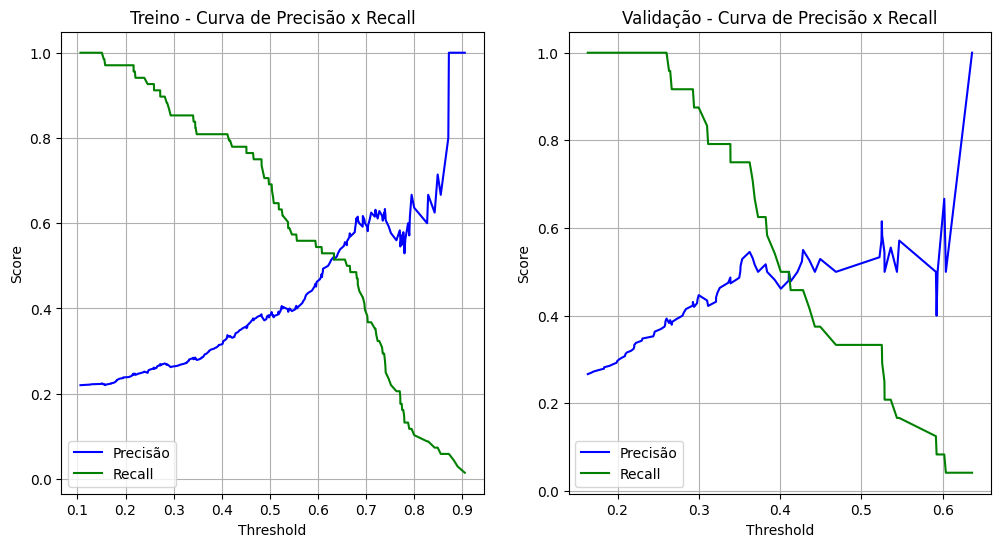

(np.float64(0.6140713984484767),
 np.float64(0.765028941554595),
 np.float64(-0.1509575431061183),
 np.float64(0.4115110593570543),
 np.float64(0.48368221375709436),
 np.float64(0.3256851134903522),
 np.float64(0.3359247294827195))

In [249]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='lbfgs', max_iter=5000,random_state=42, class_weight=class_weight, C=11, penalty='l2')

pipeline_rl = Pipeline([
    ('scaler', StandardScaler()), 
    ('modelo', modelo_rl)
])

pipeline_rl.fit(X_train_subset, y_train)
tr.comparar_auc_conjuntos(pipeline_rl, X_train_subset, y_train, X_validacao_subset, y_validacao)

In [250]:
pd.DataFrame({'feature': X_train_subset.columns
              , 'coef': modelo_rl.coef_[0]
              , 'coef_abs': np.abs(modelo_rl.coef_[0])              
              }).sort_values(by='coef_abs', ascending=False).head(20)

,feature,coef,coef_abs
0,close_norm_ultimo,-0.542311,0.542311
2,atr_pct_ultimo,0.393581,0.393581
1,retorno_acumulado_ultimos_5_dias,0.342113,0.342113
3,alpha_papel_vs_ibov_mean,0.191512,0.191512
4,cmf_ultimo,-0.121194,0.121194


Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 313583328458643828).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/313583328458643828
MLflow Run ID: a97e38d4c70844a6b8df81a573bdd6e3 para ITUB4.SA_6dias_x_0.05val_10dias_alvo
AUC no treino: 0.746
AUC na validação: 0.795

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.55
  Precisão Média Esperada: 20.26%
  Recall Médio Esperado: 25.79%
  Janelas Usadas para Precisão: 181.0

Threshold ideal baseado em mínimo recall ou precisão: 0.55

--- Conjunto de Validação --- Janelas
Precisão média (em 31 janelas com previsão positiva): 0.419
Recall médio: 0.097
Sinais de compra presentes na vallidação: 24.0
Sinais de compra previstos na validação: 6
Modelo ITUB4.SA_6dias_x_0.05val_10dias_alvo salvo na run a97e38d4c70844a6b8df81a573bdd6e3


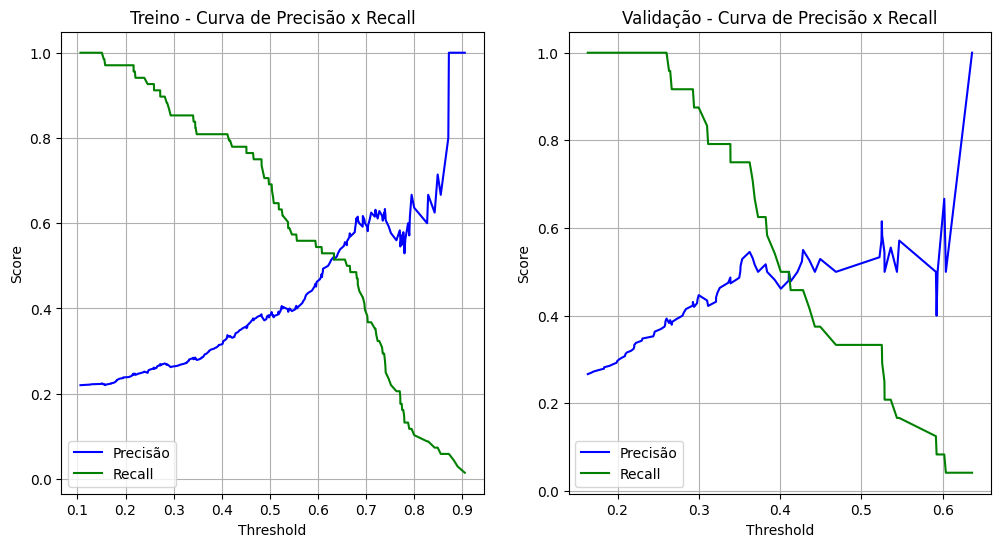

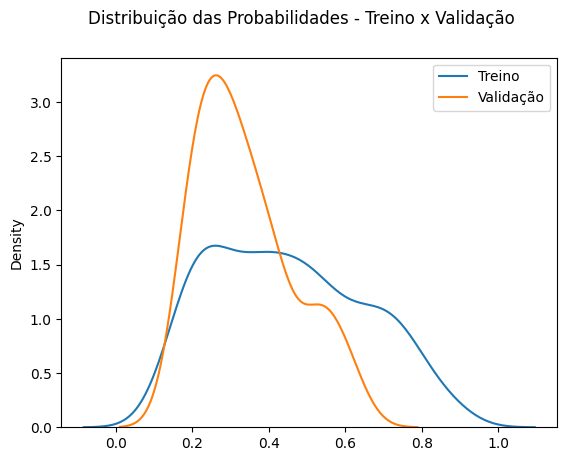

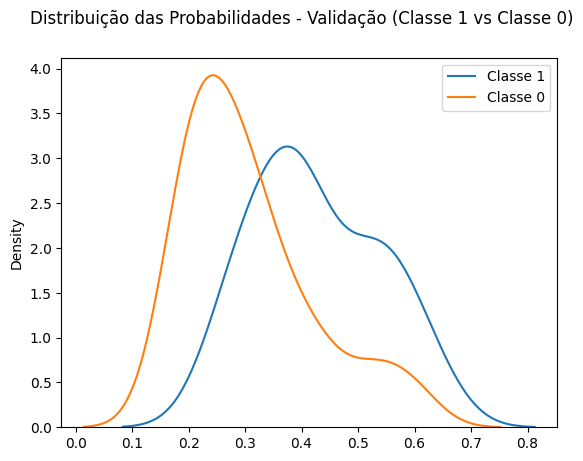

In [251]:
recall_minimo = None
precisao_minima = None
threshold_fixo = 0.55
resultado = tr.avaliar_e_logar_modelo(pipeline_rl, papel, X_train_subset, y_train, X_validacao_subset, y_validacao, dias_janela_x=dias_entrada, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima, threshold_fixo=threshold_fixo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Decisiontre

In [252]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

def encontrar_ilhas_com_arvore_decisao(
        X_treino: pd.DataFrame,
        y_treino: pd.Series,
        max_profundidade: int = 4,
        min_pureza_folha: float = 0.51, # Ex: queremos folhas com mais de 50% de sucesso
        min_amostras_folha: int = 15,    # Ex: e baseadas em pelo menos 15 amostras
        visualizar_arvore: bool = True
    ):
    """
    Usa uma árvore de decisão rasa para encontrar e extrair "ilhas" (regras)
    de alta probabilidade para o Target=1.

    Args:
        X_treino: DataFrame de features de treino.
        y_treino: Série de alvos de treino.
        max_profundidade: Profundidade máxima da árvore para manter as regras simples.
        min_pureza_folha: A proporção mínima de Target=1 em uma folha para ser considerada "promissora".
        min_amostras_folha: Número mínimo TOTAL de amostras em uma folha para ser considerada.
        visualizar_arvore: Se True, plota a árvore de decisão gerada.

    Returns:
        Um DataFrame com as regras promissoras e suas estatísticas.
    """
    print(f"\n--- Buscando 'Ilhas' com Decision Tree (max_depth={max_profundidade}) ---")
    print(f"Critérios: Pureza >= {min_pureza_folha:.0%}, Mínimo de {min_amostras_folha} amostras por folha.")
    
    # Treinar a árvore de decisão rasa
    # O min_samples_leaf na árvore já é um pré-filtro. A verificação posterior é uma garantia.
    arvore_simples = DecisionTreeClassifier(
        max_depth=max_profundidade,
        min_samples_leaf=min_amostras_folha,
        class_weight='balanced',
        random_state=42
    )
    arvore_simples.fit(X_treino, y_treino)

    # --- Visualizar a Árvore (Opcional, mas Útil) ---
    if visualizar_arvore:
        plt.figure(figsize=(24, 12)) # Tamanho maior para melhor visualização
        plot_tree(
            arvore_simples,
            feature_names=X_treino.columns.tolist(),
            class_names=['Nao_Sucesso', 'Sucesso'],
            filled=True,
            rounded=True,
            proportion=False, # Mostra contagens, não proporções
            precision=2,
            fontsize=10
        )
        plt.title(f"Árvore de Decisão para Identificação de Regras (max_depth={max_profundidade})", fontsize=16)
        plt.show()

    # --- Extrair Regras das Folhas ---
    tree_ = arvore_simples.tree_
    feature_names = X_treino.columns.tolist()
    regras_promissoras = []

    def extrair_caminho_e_regras(node_index, caminho_atual):
        # Se for uma folha (não tem filhos)
        if tree_.children_left[node_index] == tree_.children_right[node_index]:
            
            # O 'value' é um array 3D: [[[contagem_classe_0, contagem_classe_1, ...]]]
            # Corrigindo o acesso aos valores
            perc_classe0 = tree_.value[node_index][0][0]
            perc_classe1 = tree_.value[node_index][0][1]
            total_amostras_na_folha = tree_.n_node_samples[node_index] # Forma mais direta de pegar o total
            contagem_classe0 = perc_classe0 * total_amostras_na_folha
            contagem_classe1 = perc_classe1 * total_amostras_na_folha
            print(f"Folha {node_index}: {caminho_atual} -> Classe 0: {contagem_classe0}, Classe 1: {contagem_classe1}, Total: {total_amostras_na_folha}")

            # Verificação para evitar divisão por zero se a folha estiver vazia (improvável)
            if total_amostras_na_folha > 0:
                taxa_de_sucesso = contagem_classe1 / total_amostras_na_folha
                
                # Aplicar os filtros para decidir se a regra é "promissora"
                if taxa_de_sucesso >= min_pureza_folha and total_amostras_na_folha >= min_amostras_folha:
                    regra_str = " E ".join(caminho_atual) if caminho_atual else "Todas as amostras"
                    regras_promissoras.append({
                        'regra': regra_str,
                        'taxa_sucesso': taxa_de_sucesso,
                        'num_sucessos': contagem_classe1,
                        'num_total_amostras': total_amostras_na_folha
                    })
            return

        # Se não for uma folha, continuar recursivamente para os filhos
        feature_index = tree_.feature[node_index]
        feature_name = feature_names[feature_index]
        threshold_val = tree_.threshold[node_index]
        
        # Caminho da esquerda (condição <=)
        caminho_para_esquerda = caminho_atual + [f"{feature_name} <= {threshold_val:.4f}"]
        extrair_caminho_e_regras(tree_.children_left[node_index], caminho_para_esquerda)
        
        # Caminho da direita (condição >)
        caminho_para_direita = caminho_atual + [f"{feature_name} > {threshold_val:.4f}"]
        extrair_caminho_e_regras(tree_.children_right[node_index], caminho_para_direita)

    # Iniciar a extração recursiva a partir do nó raiz (índice 0)
    extrair_caminho_e_regras(0, [])
    
    if not regras_promissoras:
        print("\nNenhuma regra promissora encontrada com os critérios definidos.")
        return pd.DataFrame()
        
    df_regras = pd.DataFrame(regras_promissoras).sort_values(by=['taxa_sucesso', 'num_total_amostras'], ascending=[False, False])
    return df_regras


--- Buscando 'Ilhas' com Decision Tree (max_depth=3) ---
Critérios: Pureza >= 70%, Mínimo de 30 amostras por folha.


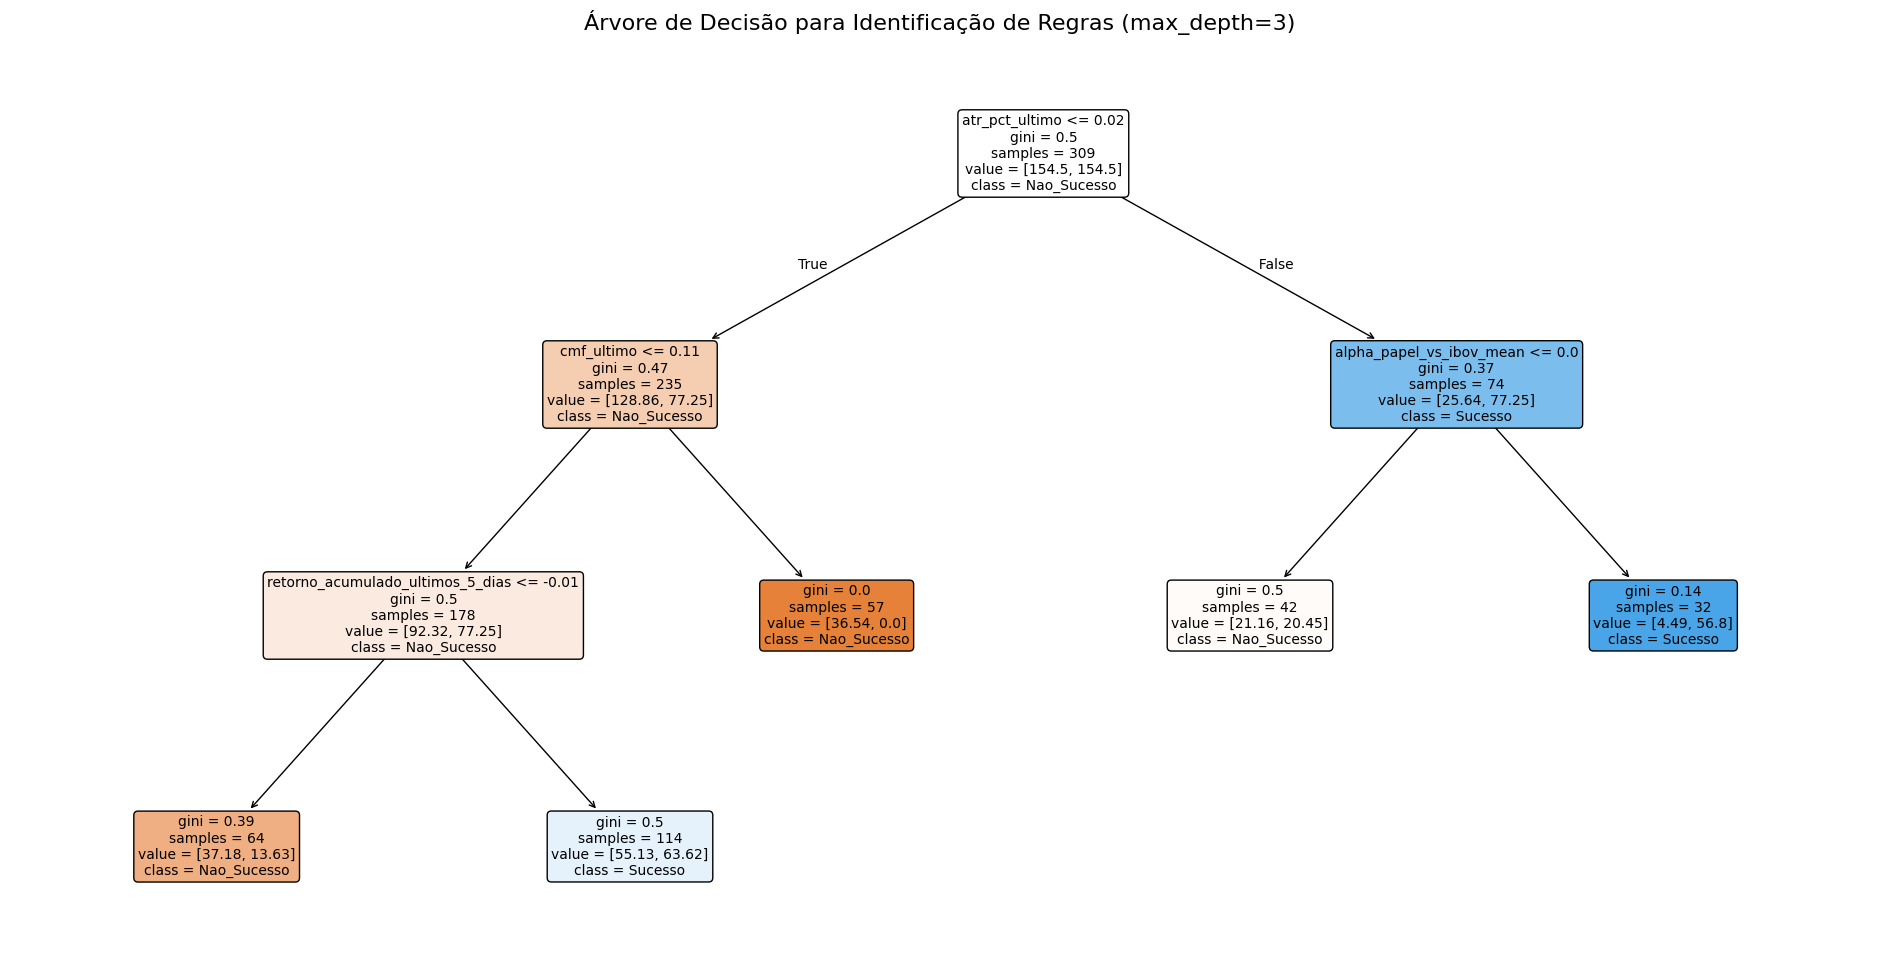

Folha 3: ['atr_pct_ultimo <= 0.0200', 'cmf_ultimo <= 0.1118', 'retorno_acumulado_ultimos_5_dias <= -0.0061'] -> Classe 0: 46.830426716141005, Classe 1: 17.169573283859005, Total: 64
Folha 4: ['atr_pct_ultimo <= 0.0200', 'cmf_ultimo <= 0.1118', 'retorno_acumulado_ultimos_5_dias > -0.0061'] -> Classe 0: 52.92727850111137, Classe 1: 61.07272149888848, Total: 114
Folha 5: ['atr_pct_ultimo <= 0.0200', 'cmf_ultimo > 0.1118'] -> Classe 0: 57.0, Classe 1: 0.0, Total: 57
Folha 7: ['atr_pct_ultimo > 0.0200', 'alpha_papel_vs_ibov_mean <= 0.0025'] -> Classe 0: 21.356900067980966, Classe 1: 20.64309993201904, Total: 42
Folha 8: ['atr_pct_ultimo > 0.0200', 'alpha_papel_vs_ibov_mean > 0.0025'] -> Classe 0: 2.3430241501307485, Classe 1: 29.65697584986925, Total: 32

--- Regras Promissoras Encontradas ---
                                                         regra  taxa_sucesso  num_sucessos  num_total_amostras
0  atr_pct_ultimo > 0.0200 E alpha_papel_vs_ibov_mean > 0.0025       0.92678     29.65697

In [253]:
# Chamar a função para encontrar as regras
regras_encontradas_df = encontrar_ilhas_com_arvore_decisao(
    X_treino=X_train_subset,
    y_treino=y_train,
    max_profundidade=3,
    min_pureza_folha=0.70, # Buscar folhas com pelo menos 50% de sucesso
    min_amostras_folha=30   # E que tenham pelo menos 15 amostras
)

print("\n--- Regras Promissoras Encontradas ---")
if not regras_encontradas_df.empty:
    print(regras_encontradas_df.to_string())
else:
    print("Nenhuma regra encontrada.")

In [254]:
X_train_subset['cmf_ultimo_x_atr_pct_ultimo'] = X_train_subset['cmf_ultimo'] * X_train_subset['atr_pct_ultimo']
X_validacao_subset['cmf_ultimo_x_atr_pct_ultimo'] = X_validacao_subset['cmf_ultimo'] * X_validacao_subset['atr_pct_ultimo']

X_train_subset['cmf_ultimo_x_atr_pct_ultimo_x_alpha_papel_vs_ibov_mean'] = X_train_subset['cmf_ultimo'] * X_train_subset['atr_pct_ultimo'] * X_train_subset['alpha_papel_vs_ibov_mean']
X_validacao_subset['cmf_ultimo_x_atr_pct_ultimo_x_alpha_papel_vs_ibov_mean'] = X_validacao_subset['cmf_ultimo'] * X_validacao_subset['atr_pct_ultimo'] * X_validacao_subset['alpha_papel_vs_ibov_mean']



In [255]:
modelo_otimizado = tr.otimizar_hiperparametros_logreg(X_train_subset, y_train, n_splits_cv=5, pipeline_template=pipeline)
modelo_otimizado


--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits=5) ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits

--- Resultados da Otimização ---
Melhor Score (make_scorer(f1_score, response_method='predict')): 0.1739
Melhores Parâmetros Encontrados:
{'modelo__C': np.float64(0.0001), 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}


Pipeline(steps=[('scaler', StandardScaler()),
                ('modelo',
                 LogisticRegression(C=np.float64(0.0001), max_iter=5000,
                                    random_state=42, solver='liblinear'))])

AUC no treino: 0.624
AUC na validação: 0.813
Diferença AUC (Treino - Validação): -0.189
PR AUC no treino: 0.433
PR AUC na validação: 0.604
Diferença PR AUC (Treino - Validação): -0.171
F1 Score no treino: 0.301
F1 Score na validação: 0.272


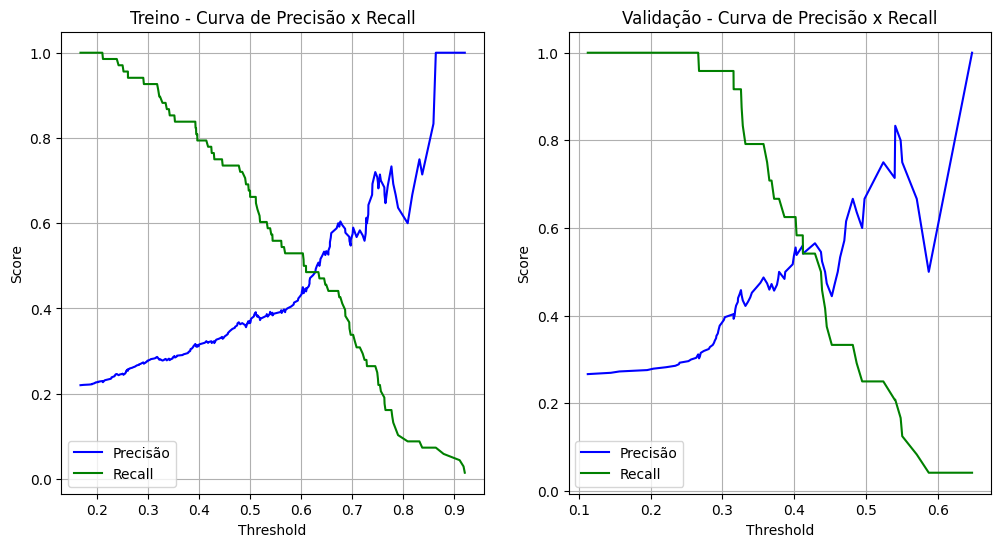

(np.float64(0.6243819352862592),
 np.float64(0.8132209165495465),
 np.float64(-0.18883898126328735),
 np.float64(0.4325084285972634),
 np.float64(0.6035558647648948),
 np.float64(0.3006855091430121),
 np.float64(0.2720416124321816))

In [256]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='liblinear', max_iter=5000,random_state=42, class_weight=class_weight, C=0.1, penalty='l2')

pipeline_rl = Pipeline([
    ('scaler', StandardScaler()), 
    ('modelo', modelo_rl)
])

pipeline_rl.fit(X_train_subset, y_train)
tr.comparar_auc_conjuntos(pipeline_rl, X_train_subset, y_train, X_validacao_subset, y_validacao)

In [257]:
pd.DataFrame({'feature': X_train_subset.columns
              , 'coef': modelo_rl.coef_[0]
              , 'coef_abs': np.abs(modelo_rl.coef_[0])              
              }).sort_values(by='coef_abs', ascending=False).head(20)

,feature,coef,coef_abs
0,close_norm_ultimo,-0.425998,0.425998
2,atr_pct_ultimo,0.380280,0.380280
1,retorno_acumulado_ultimos_5_dias,0.246390,0.246390
3,alpha_papel_vs_ibov_mean,0.208248,0.208248
6,cmf_ultimo_x_atr_pct_ultimo_x_alpha_papel_vs_i...,-0.188525,0.188525
4,cmf_ultimo,-0.114896,0.114896
5,cmf_ultimo_x_atr_pct_ultimo,0.001936,0.001936


Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 313583328458643828).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/313583328458643828
MLflow Run ID: 67e632184f8d46268ef4497c07184d4f para ITUB4.SA_6dias_x_0.05val_10dias_alvo
AUC no treino: 0.744
AUC na validação: 0.794

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.624
  Precisão média (em 249 janelas com previsão positiva): 0.281
  Recall médio: 0.376

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 28.08%
  Recall Médio Esperado: 37.61%
  Janelas Usadas para Precisão: 249.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 23 janelas com previsão positiva): 0.759
Recall médio: 0.131
Sinais de compra presentes na vallidação: 24.0
Sinais de compra previstos na validação: 8
Modelo ITUB4.SA_6dias_x_0.05val_10dias_alvo salvo na run 67e632184f8d46268ef4497c

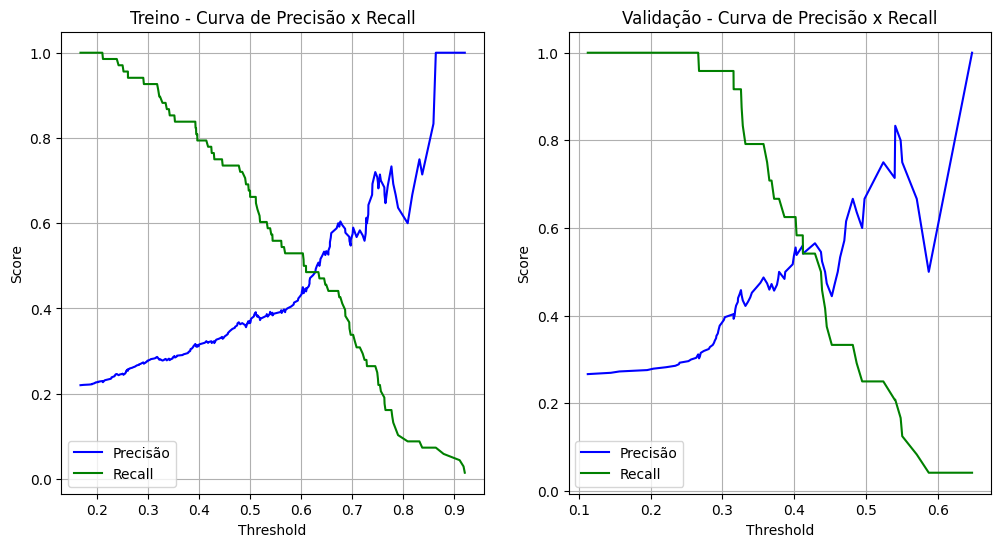

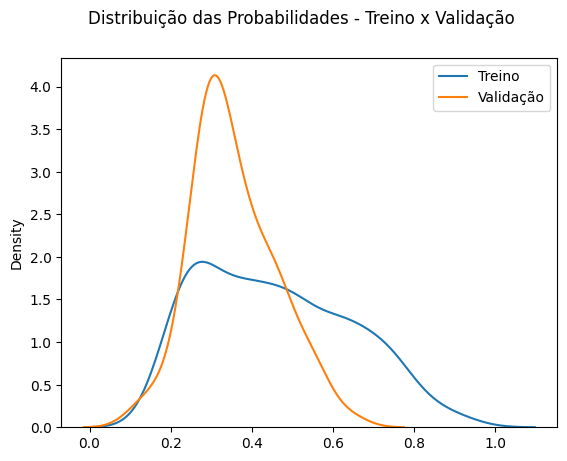

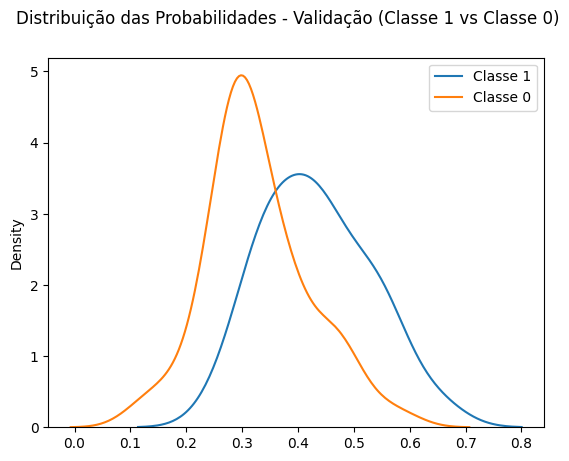

In [258]:
recall_minimo = None
precisao_minima = None
threshold_fixo = 0.50
resultado = tr.avaliar_e_logar_modelo(pipeline_rl, papel, X_train_subset, y_train, X_validacao_subset, y_validacao, dias_janela_x=dias_entrada, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima, threshold_fixo=threshold_fixo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# acréscimo de variáveis com informação mútua

In [259]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone

def ranquear_features_por_info_mutua(X: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """
    Calcula a Informação Mútua entre cada feature em X e o alvo y,
    e retorna um DataFrame com as features ranqueadas.

    Args:
        X (pd.DataFrame): DataFrame de features.
        y (pd.Series): Série com os alvos.

    Returns:
        pd.DataFrame: DataFrame com as colunas 'feature' e 'mutual_info_score',
                      ordenado do maior para o menor score.
    """
    print("\n--- Calculando Informação Mútua para todas as features... ---")
    # A Informação Mútua funciona melhor com dados discretos ou binarizados,
    # mas o sklearn a adapta para contínuos. Ela pode levar um tempo para calcular.
    # É importante passar dados sem NaNs.
    X_limpo = X.fillna(X.mean()) # Estratégia simples para lidar com NaNs para este cálculo

    # Para features categóricas/discretas, podemos passar essa informação para a função
    # mas para este caso, o tratamento padrão para contínuas é suficiente.
    mi_scores = mutual_info_classif(X_limpo, y, random_state=42)

    df_mi_scores = pd.DataFrame({
        'feature': X.columns,
        'mutual_info_score': mi_scores
    }).sort_values(by='mutual_info_score', ascending=False).reset_index(drop=True)

    print("Ranking de Features por Informação Mútua (Top 15):")
    print(df_mi_scores.head(15).to_string())
    
    return df_mi_scores

def avaliar_adicao_incremental_de_features(
        X_treino_completo, y_treino,
        X_validacao_completo, y_validacao,
        ranking_features_df,
        modelo_template,
        max_features_a_testar=20
    ):
    """
    Treina e avalia um modelo, adicionando features uma por uma,
    na ordem definida por um ranking pré-calculado.

    Args:
        X_treino_completo: DataFrame de treino com todas as features.
        y_treino: Alvos de treino.
        X_validacao_completo: DataFrame de validação com todas as features.
        y_validacao: Alvos de validação.
        ranking_features_df: DataFrame ranqueado retornado por ranquear_features_por_info_mutua.
        modelo_template: Modelo não treinado a ser usado (ex: Pipeline).
        max_features_a_testar (int): Número máximo de features a serem testadas.

    Returns:
        pd.DataFrame: Um DataFrame com os resultados de performance para cada número de features.
    """
    print(f"\n--- Iniciando Avaliação Incremental (até {max_features_a_testar} features)... ---")
    
    resultados_incrementais = []
    lista_features_ranqueadas = ranking_features_df['feature'].tolist()

    for k in range(1, min(max_features_a_testar + 1, len(lista_features_ranqueadas) + 1)):
        features_atuais = lista_features_ranqueadas[:k]
        
        X_treino_subset = X_treino_completo[features_atuais]
        X_validacao_subset = X_validacao_completo[features_atuais]
        
        # Clonar e treinar o modelo
        modelo = clone(modelo_template)
        try:
            modelo.fit(X_treino_subset, y_treino)
        except Exception as e:
            print(f"Erro no fit com k={k}: {e}")
            continue

        # Avaliar no treino e na validação
        y_pred_treino = modelo.predict(X_treino_subset)
        y_pred_validacao = modelo.predict(X_validacao_subset)

        f1_treino = f1_score(y_treino, y_pred_treino, zero_division=0)
        f1_validacao = f1_score(y_validacao, y_pred_validacao, zero_division=0)
        
        print(f"k={k:<3} | Feature Adicionada: {features_atuais[-1]:<40} | F1 Treino: {f1_treino:.3f} | F1 Validação: {f1_validacao:.3f}")
        
        resultados_incrementais.append({
            'num_features_k': k,
            'ultima_feature_adicionada': features_atuais[-1],
            'f1_treino': f1_treino,
            'f1_validacao': f1_validacao
        })
        
    return pd.DataFrame(resultados_incrementais)





--- Calculando Informação Mútua para todas as features... ---
Ranking de Features por Informação Mútua (Top 15):
                     feature  mutual_info_score
0             close_norm_min           0.251897
1             close_norm_max           0.192851
2            close_norm_mean           0.149285
3               dolar_ultimo           0.103179
4                   obv_mean           0.102963
5               selic_ultimo           0.093634
6                ipca_ultimo           0.091782
7       adc_adx_ultimo_BBDC4           0.090444
8                 obv_ultimo           0.089452
9                  rsi_trend           0.087367
10               macd_ultimo           0.079935
11                adx_ultimo           0.078204
12         retorno_medio_neg           0.077153
13              atr_pct_mean           0.073625
14  selic_dias_desde_mudanca           0.070730

--- Iniciando Avaliação Incremental (até 20 features)... ---
k=1   | Feature Adicionada: close_norm_min              

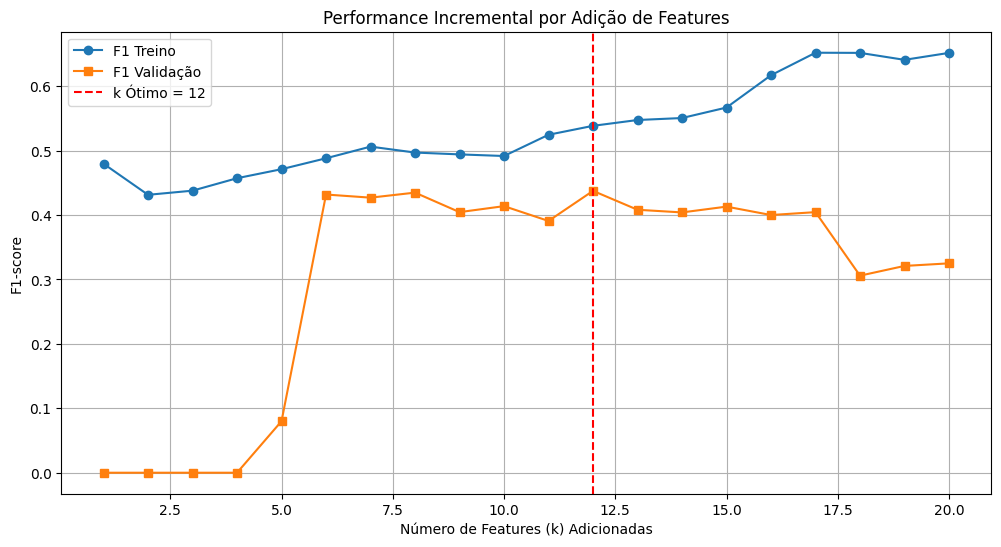

In [260]:
# --- Passo 1: Ranquear TODAS as features usando Informação Mútua (apenas nos dados de treino) ---
ranking_de_features = ranquear_features_por_info_mutua(X_train, y_train)

# --- Passo 2: Definir o modelo a ser usado (com Pipeline para robustez) ---
# Usar um modelo com regularização razoável, pois o número de features vai crescer.
modelo_teste_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        solver='liblinear',
        penalty='l2',
        C=0.1, # Um C razoavelmente regularizador
        random_state=42,
        class_weight='balanced'
    ))
])

# --- Passo 3: Executar a avaliação incremental ---
df_performance_incremental = avaliar_adicao_incremental_de_features(
    X_treino_completo=X_train,
    y_treino=y_train,
    X_validacao_completo=X_validacao,
    y_validacao=y_validacao,
    ranking_features_df=ranking_de_features,
    modelo_template=modelo_teste_pipeline,
    max_features_a_testar=20 # Testar até as top 20 features
)

# --- Passo 4: Analisar os resultados ---
print("\n--- Resultado da Avaliação Incremental de Features ---")
print(df_performance_incremental.round(3).to_string())

if not df_performance_incremental.empty:
    # Encontrar o número de features (k) que maximizou o F1-score NA VALIDAÇÃO
    k_otimo = df_performance_incremental.loc[df_performance_incremental['f1_validacao'].idxmax()]
    print("\n--- Melhor Conjunto de Features Encontrado ---")
    print(k_otimo)
    
    # Plotar para visualização
    plt.figure(figsize=(12, 6))
    plt.plot(df_performance_incremental['num_features_k'], df_performance_incremental['f1_treino'], marker='o', label='F1 Treino')
    plt.plot(df_performance_incremental['num_features_k'], df_performance_incremental['f1_validacao'], marker='s', label='F1 Validação')
    plt.xlabel("Número de Features (k) Adicionadas")
    plt.ylabel("F1-score")
    plt.title("Performance Incremental por Adição de Features")
    plt.legend()
    plt.grid(True)
    # Adicionar uma linha vertical no k ótimo
    plt.axvline(x=k_otimo['num_features_k'], color='r', linestyle='--', label=f'k Ótimo = {int(k_otimo["num_features_k"])}')
    plt.legend() # Chamar de novo para incluir a linha
    plt.show()

In [261]:
colunas_adicionais = df_performance_incremental.head(10)['ultima_feature_adicionada'].values

In [262]:
colunas = features + colunas_adicionais.tolist()

X_train_subset = X_train[colunas].copy()
X_validacao_subset = X_validacao[colunas].copy()

In [263]:
modelo_otimizado = tr.otimizar_hiperparametros_logreg(X_train_subset, y_train, n_splits_cv=5, pipeline_template=pipeline)
modelo_otimizado


--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits=5) ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits

--- Resultados da Otimização ---
Melhor Score (make_scorer(f1_score, response_method='predict')): 0.3163
Melhores Parâmetros Encontrados:
{'modelo__C': np.float64(0.0001), 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}


Pipeline(steps=[('scaler', StandardScaler()),
                ('modelo',
                 LogisticRegression(C=np.float64(0.0001), max_iter=5000,
                                    random_state=42, solver='liblinear'))])

AUC no treino: 0.750
AUC na validação: 0.711
Diferença AUC (Treino - Validação): 0.040
PR AUC no treino: 0.567
PR AUC na validação: 0.472
Diferença PR AUC (Treino - Validação): 0.095
F1 Score no treino: 0.389
F1 Score na validação: 0.360


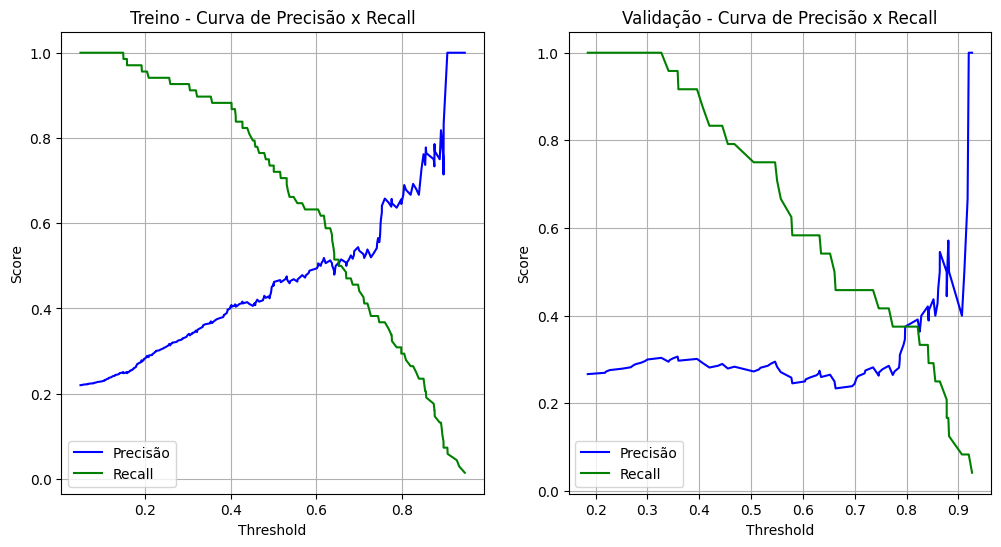

(np.float64(0.7504866323899393),
 np.float64(0.7107076906618842),
 np.float64(0.03977894172805507),
 np.float64(0.5667109800752118),
 np.float64(0.47218402915895824),
 np.float64(0.3885767193078322),
 np.float64(0.3599233945137849))

In [264]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='saga', max_iter=5000,random_state=42, class_weight=class_weight, C=1, penalty='l1')

pipeline_rl = Pipeline([
    ('scaler', StandardScaler()), 
    ('modelo', modelo_rl)
])

pipeline_rl.fit(X_train_subset, y_train)
tr.comparar_auc_conjuntos(pipeline_rl, X_train_subset, y_train, X_validacao_subset, y_validacao)

In [265]:
pd.DataFrame({'feature': X_train_subset.columns
              , 'coef': modelo_rl.coef_[0]
              , 'coef_abs': np.abs(modelo_rl.coef_[0])              
              }).sort_values(by='coef_abs', ascending=False).head(20)

,feature,coef,coef_abs
13,obv_ultimo,-1.560194,1.560194
10,selic_ultimo,1.265994,1.265994
9,obv_mean,0.592511,0.592511
8,dolar_ultimo,-0.423500,0.423500
4,cmf_ultimo,-0.293460,0.293460
11,ipca_ultimo,-0.240994,0.240994
1,retorno_acumulado_ultimos_5_dias,0.235302,0.235302
3,alpha_papel_vs_ibov_mean,0.234217,0.234217
5,close_norm_min,0.201272,0.201272
14,rsi_trend,0.193455,0.193455


Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 313583328458643828).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/313583328458643828
MLflow Run ID: 694f3e92b84d478db4a29b14e4e978d3 para ITUB4.SA_6dias_x_0.05val_10dias_alvo
AUC no treino: 0.812
AUC na validação: 0.564

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.750
  Precisão média (em 210 janelas com previsão positiva): 0.490
  Recall médio: 0.432

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 49.04%
  Recall Médio Esperado: 43.17%
  Janelas Usadas para Precisão: 210.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.166
Recall médio: 0.520
Sinais de compra presentes na vallidação: 24.0
Sinais de compra previstos na validação: 66
Modelo ITUB4.SA_6dias_x_0.05val_10dias_alvo salvo na run 694f3e92b84d478db4a29b1

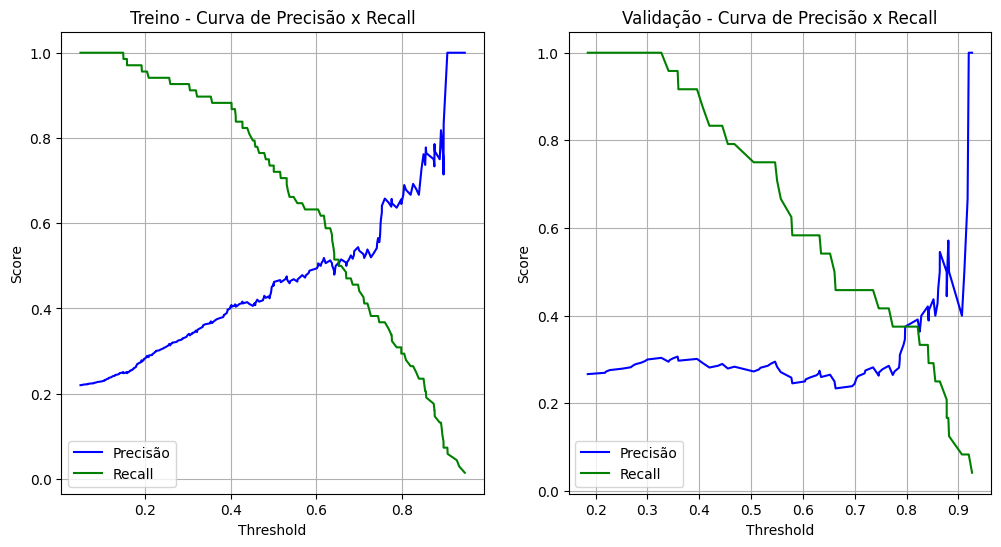

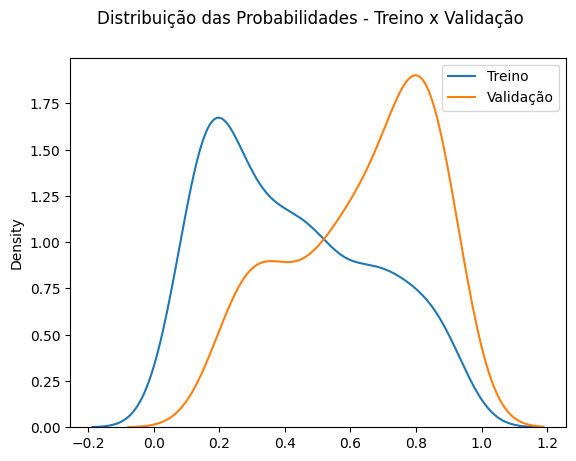

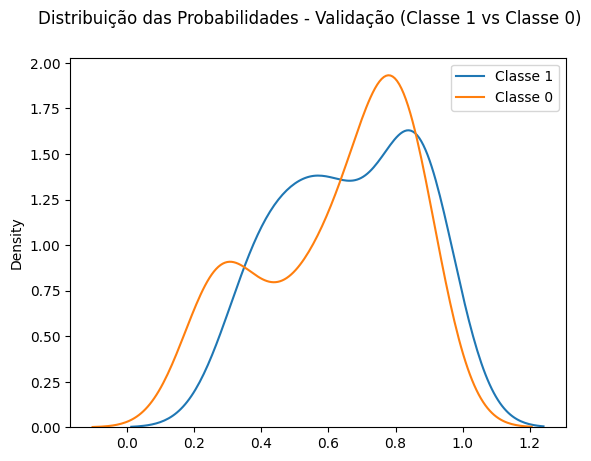

In [266]:
recall_minimo = None
precisao_minima = None
threshold_fixo = 0.5
resultado = tr.avaliar_e_logar_modelo(pipeline_rl, papel, X_train_subset, y_train, X_validacao_subset, y_validacao, dias_janela_x=dias_entrada, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima, threshold_fixo=threshold_fixo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Re avaliação do X para entender por onde pode ser um novo começo

In [267]:
X.head()

,close_norm_mean,close_norm_std,close_norm_max,close_norm_min,close_norm_trend,close_norm_ultimo,retorno_acumulado_ultimos_5_dias,retorno_mean,retorno_std,dias_alta_pct,dias_queda_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,correl_retorno_volume,rsi_mean,rsi_std,rsi_ultimo,rsi_trend,macd_mean,macd_std,macd_ultimo,macd_trend,macd_signal_mean,macd_signal_std,macd_signal_ultimo,macd_signal_trend,macd_hist_mean,macd_hist_std,macd_hist_ultimo,macd_hist_trend,obv_mean,obv_std,obv_ultimo,obv_trend,cmf_mean,cmf_std,cmf_ultimo,cmf_trend,atr_pct_mean,atr_pct_std,atr_pct_ultimo,atr_pct_trend,adx_ultimo,adx_trend,tendencia_forte_adx25,bbands_largura_pct_ultimo,bbands_largura_pct_trend,bbands_posicao_pct_ultimo,bbands_exaustao_compra,bbands_exaustao_venda,adc_close_norm_trend_BBAS3,adc_correl_com_principal_BBAS3,adc_adx_ultimo_BBAS3,adc_close_norm_trend_BBDC4,adc_correl_com_principal_BBDC4,adc_adx_ultimo_BBDC4,adc_close_norm_trend_SANB11,adc_correl_com_principal_SANB11,adc_adx_ultimo_SANB11,adc_close_norm_mean_geral_ultimo,selic_ultimo,selic_comparacao_anterior,selic_dias_desde_mudanca,ipca_ultimo,ipca_comparacao_anterior,ipca_dias_desde_mudanca,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,ibov_std,retorno_desde_mudanca_ibov,ibov_amplitude,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean,regime_tendencia,regime_volatilidade,close_norm_vs_adc_norm_mean_geral,retorno_acumulado_norm,dia_semana_0,dia_semana_1,dia_semana_2,dia_semana_3,dia_semana_4,feriado,proximo_dia_util
2024-01-26,1.141424,0.009825,1.158385,1.130590,-0.002632,1.145693,0.012654,-0.000209,0.010413,0.500000,0.500000,0.007304,-0.007721,2.621170e+07,9.653828e+06,-4.641739e+06,-0.392794,-0.690121,47.375340,4.037016,51.886446,-0.262589,0.145715,0.087508,0.059080,-0.045642,0.325396,0.086810,0.213633,-0.046379,-0.179681,0.016813,-0.154553,0.000737,5.487710e+08,2.136038e+07,539063030.0,-8.542022e+06,0.045057,0.054998,-0.021842,-0.026350,0.016711,0.000732,0.016847,0.000239,22.304308,-0.523250,0,5.268630,0.236883,0.342807,0,0,0.002887,0.700997,25.796966,-0.002523,0.836570,36.332532,-0.007073,0.672959,29.762013,1.061826,11.75,-1.0,44,0.42,-1.0,29,4.9125,-0.005106,0.022625,0.000000,311.685714,787.871415,0.006226,2365.0,0.794237,1.108252,-0.003069,0,0,0.078984,-0.010957,0,0,0,0,1,0,False
2024-01-29,1.138055,0.005243,1.145693,1.130590,0.000296,1.138173,0.002765,-0.001478,0.010491,0.333333,0.666667,0.009738,-0.007086,2.198678e+07,1.053687e+07,-5.244602e+06,-0.560366,-0.579080,46.754198,3.228754,49.140754,1.088067,0.106338,0.064860,0.044408,-0.033123,0.281584,0.081993,0.179788,-0.043728,-0.175247,0.024269,-0.135379,0.010605,5.399677e+08,1.464977e+07,529396890.0,-4.620607e+06,0.021957,0.063536,-0.054048,-0.032609,0.016944,0.000234,0.016666,-0.000056,21.047092,-0.880150,0,4.786164,0.085341,0.261118,0,0,0.001473,0.686292,25.623473,-0.000629,0.836535,36.085348,-0.006858,0.776621,30.486930,1.049233,11.75,-1.0,47,0.42,-1.0,32,4.9225,-0.008729,0.022606,0.000000,342.000000,807.096194,0.000000,2365.0,0.671827,0.802654,-0.000907,0,0,0.084766,0.000273,1,0,0,0,0,0,True
2024-01-30,1.136658,0.006313,1.145693,1.129479,-0.000968,1.129479,0.000926,0.000182,0.008195,0.333333,0.666667,0.009738,-0.004596,1.918261e+07,6.105964e+06,-1.487810e+06,0.205753,-0.119043,47.019574,3.048754,45.908882,0.479792,0.074637,0.050486,0.017178,-0.025651,0.240195,0.075336,0.147266,-0.040112,-0.165558,0.029164,-0.130088,0.014461,5.339686e+08,1.993784e+07,506267410.0,-8.976028e+06,-0.005392,0.063086,-0.072898,-0.032311,0.016847,0.000290,0.016479,-0.000100,20.166378,-1.084715,0,4.819538,-0.043792,0.164498,0,0,-0.002978,0.655804,25.226509,-0.001072,0.797948,36.079032,-0.004690,0.371226,31.160067,1.047335,11.75,-1.0,48,0.42,-1.0,33,4.9638,-0.001123,0.025345,0.008390,-41.314286,541.889534,-0.008568,1565.0,0.832842,1.261541,0.000974,0,0,0.078432,-0.010464,0,1,0,0,0,0,True
2024-01-31,1.136463,0.006152,1.145693,1.129479,0.000498,1.140251,0.013919,0.00

In [268]:
features = ['close_norm_ultimo', 'retorno_acumulado_norm', 'atr_pct_ultimo', 'cmf_ultimo', 'alpha_papel_vs_ibov_mean']

In [269]:
X_train_subset = X_train[features].copy()
X_validacao_subset = X_validacao[features].copy()

In [270]:
X_train_subset.head()

,close_norm_ultimo,retorno_acumulado_norm,atr_pct_ultimo,cmf_ultimo,alpha_papel_vs_ibov_mean
2024-01-26,1.145693,-0.010957,0.016847,-0.021842,-0.003069
2024-01-29,1.138173,0.000273,0.016666,-0.054048,-0.000907
2024-01-30,1.129479,-0.010464,0.016479,-0.072898,0.000974
2024-01-31,1.140251,0.004987,0.017099,-0.044481,0.002490
2024-02-01,1.135728,0.004545,0.017713,-0.031341,0.001721


In [271]:
def avaliar_conjunto_de_features_walk_forward_rolante(
        X_treino_subset: pd.DataFrame,
        y_treino: pd.Series,
        modelo_template,
        tamanho_janela_treino: int = 126, # Aprox. 6 meses (21 * 6)
        tamanho_janela_validacao: int = 21  # Aprox. 1 mês
    ) -> dict:
    """
    Função auxiliar que avalia um ÚNICO conjunto de features usando
    walk-forward com JANELA ROLANTE (tamanho de treino fixo).
    Retorna a média das métricas.
    """
    # O passo de deslizamento será igual ao tamanho da janela de validação
    # para evitar sobreposição nos conjuntos de teste.
    passo_wf = tamanho_janela_validacao

    f1s, precisions, recalls = [], [], []
    num_janelas_executadas = 0

    X_wf_array = X_treino_subset.values
    y_wf_array = y_treino.values
    n_total_amostras = len(X_wf_array)
    
    # Loop de walk-forward com janela rolante
    for inicio_treino_idx in range(0, n_total_amostras, passo_wf):
        fim_treino_idx = inicio_treino_idx + tamanho_janela_treino
        inicio_validacao_idx = fim_treino_idx
        fim_validacao_idx = inicio_validacao_idx + tamanho_janela_validacao

        if fim_validacao_idx > n_total_amostras:
            break # Não há mais dados suficientes para uma janela completa
            
        num_janelas_executadas += 1

        X_treino_fold = X_wf_array[inicio_treino_idx : fim_treino_idx]
        y_treino_fold = y_wf_array[inicio_treino_idx : fim_treino_idx]
        X_teste_fold = X_wf_array[inicio_validacao_idx : fim_validacao_idx]
        y_teste_fold = y_wf_array[inicio_validacao_idx : fim_validacao_idx]
        
        # Pular se a janela de treino for muito pequena (acontece no início se o total de dados for menor que o tamanho da janela)
        # ou se não houver exemplos positivos para treinar
        if len(X_treino_fold) < tamanho_janela_treino or np.sum(y_treino_fold) == 0:
            continue
        
        modelo = clone(modelo_template)
        try:
            modelo.fit(X_treino_fold, y_treino_fold)
            y_pred = modelo.predict(X_teste_fold)
            
            f1s.append(f1_score(y_teste_fold, y_pred, zero_division=0))
            precisions.append(precision_score(y_teste_fold, y_pred, zero_division=0))
            recalls.append(recall_score(y_teste_fold, y_pred, zero_division=0))
        except Exception as e:
            # print(f"  Aviso: Erro no fit/predict do fold {num_janelas_executadas}: {e}")
            f1s.append(0); precisions.append(0); recalls.append(0)

    if not f1s: return {'f1_medio': 0, 'precisao_media': 0, 'recall_medio': 0}
    
    return {
        'f1_medio': np.mean(f1s),
        'precisao_media': np.mean(precisions),
        'recall_medio': np.mean(recalls)
    }


def encontrar_melhor_conjunto_features_incremental(
        X_super_treino, y_super_treino,
        grupos_de_features_candidatas,
        modelo_template,
        tamanho_janela_treino_wf: int = 126, # Passando os novos parâmetros
        tamanho_janela_validacao_wf: int = 21
    ):
    """
    Testa a adição de grupos de features um a um, usando a validação
    walk-forward com janela rolante.
    """
    print("\n--- Iniciando Busca Incremental pelo Melhor Conjunto de Features (Janela Rolante) ---")
    
    features_campeas = []
    melhor_score_ate_agora = -1
    resultados_busca = []
    
    grupos_para_testar = {'baseline': []}
    grupos_para_testar.update(grupos_de_features_candidatas)
    
    for nome_grupo, features_do_grupo in grupos_para_testar.items():
        print(f"\n>>> Testando adição do grupo: '{nome_grupo}'")
        
        features_atuais_teste = sorted(list(set(features_campeas + features_do_grupo)))
        features_atuais_teste = [f for f in features_atuais_teste if f in X_super_treino.columns]
        
        if not features_atuais_teste and nome_grupo != 'baseline':
             print(f"  Aviso: Nenhuma feature do grupo '{nome_grupo}' encontrada. Pulando.")
             continue

        X_subset = X_super_treino[features_atuais_teste] if features_atuais_teste else X_super_treino.iloc[:, :0]

        # Chamar a nova função de avaliação com janela rolante
        metricas_atuais = avaliar_conjunto_de_features_walk_forward_rolante(
            X_subset, y_super_treino, modelo_template,
            tamanho_janela_treino=tamanho_janela_treino_wf,
            tamanho_janela_validacao=tamanho_janela_validacao_wf
        )
        
        score_atual = metricas_atuais['f1_medio']
        print(f"  Conjunto com {len(features_atuais_teste)} features. F1-médio (WF Rolante): {score_atual:.4f}")

        if score_atual > melhor_score_ate_agora:
            print(f"  MELHORA! Score atual ({score_atual:.4f}) > Melhor anterior ({melhor_score_ate_agora:.4f}). Mantendo o grupo.")
            melhor_score_ate_agora = score_atual
            features_campeas = features_atuais_teste
            status = "Mantido"
        else:
            print(f"  Sem melhora. Score atual ({score_atual:.4f}) <= Melhor anterior ({melhor_score_ate_agora:.4f}). Descartando o grupo.")
            status = "Descartado"
            
        resultados_busca.append({
            'grupo_testado': nome_grupo,
            'f1_medio_com_grupo': score_atual,
            'status': status,
            'num_features_acumulado': len(features_campeas)
        })

    print("\n--- Conclusão da Busca Incremental ---")
    print(f"Melhor F1-score médio (WF Rolante) encontrado: {melhor_score_ate_agora:.4f}")
    print(f"Número de features no conjunto campeão: {len(features_campeas)}")
    print("Features Campeãs:")
    print(features_campeas)

    return features_campeas, pd.DataFrame(resultados_busca)

In [272]:
GRUPOS_CANDIDATOS = {
    'heroicas': [
        'close_norm_ultimo', 'retorno_acumulado_norm', 'atr_pct_ultimo',
        'cmf_ultimo', 'alpha_papel_vs_ibov_mean'
    ],
    'dinamica_momentum': [
        'rsi_trend', 'macd_hist_trend'
    ],
    'dinamica_volume': [
        'volume_trend', 'correl_retorno_volume', 'obv_trend'
    ],
    'contexto_mercado': [
        'adx_ultimo', 'bbands_largura_pct_ultimo', 'ibov_trend', 'dolar_trend'
    ],
    'pares': [
        'adc_close_norm_mean_geral_ultimo', 'close_norm_vs_adc_norm_mean_geral'
    ]
    , 'regimes': [
        'regime_tendencia', 'regime_volatilidade'
    ]
}

# 3. Definir o modelo template (simples e regularizado)
modelo_base_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        solver='liblinear', penalty='l2', C=0.1, random_state=42, class_weight='balanced'
    ))
])

#4. Executar a busca
#Supondo que X_train e y_train estão definidos
features_campeas_finais, df_resultados_busca = encontrar_melhor_conjunto_features_incremental(
    X_train, y_train,
    GRUPOS_CANDIDATOS,
    modelo_base_pipeline
    
) 

features_campeas_finais


--- Iniciando Busca Incremental pelo Melhor Conjunto de Features (Janela Rolante) ---

>>> Testando adição do grupo: 'baseline'
  Conjunto com 0 features. F1-médio (WF Rolante): 0.0000
  MELHORA! Score atual (0.0000) > Melhor anterior (-1.0000). Mantendo o grupo.

>>> Testando adição do grupo: 'heroicas'
  Conjunto com 5 features. F1-médio (WF Rolante): 0.3290
  MELHORA! Score atual (0.3290) > Melhor anterior (0.0000). Mantendo o grupo.

>>> Testando adição do grupo: 'dinamica_momentum'
  Conjunto com 7 features. F1-médio (WF Rolante): 0.2952
  Sem melhora. Score atual (0.2952) <= Melhor anterior (0.3290). Descartando o grupo.

>>> Testando adição do grupo: 'dinamica_volume'
  Conjunto com 8 features. F1-médio (WF Rolante): 0.2942
  Sem melhora. Score atual (0.2942) <= Melhor anterior (0.3290). Descartando o grupo.

>>> Testando adição do grupo: 'contexto_mercado'
  Conjunto com 9 features. F1-médio (WF Rolante): 0.3149
  Sem melhora. Score atual (0.3149) <= Melhor anterior (0.3290). 

['alpha_papel_vs_ibov_mean',
 'atr_pct_ultimo',
 'close_norm_ultimo',
 'cmf_ultimo',
 'regime_tendencia',
 'regime_volatilidade',
 'retorno_acumulado_norm']

In [273]:
X_train_subset = X_train[features_campeas_finais].copy()
X_validacao_subset = X_validacao[features_campeas_finais].copy()

In [274]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Criar um pipeline com o scaler e o modelo
pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Normalização     
    ('modelo', LogisticRegression(solver='liblinear', max_iter=5000, random_state=42))
])

In [275]:
modelo_otimizado = tr.otimizar_hiperparametros_logreg(X_train_subset, y_train, n_splits_cv=5, pipeline_template=pipeline)
modelo_otimizado


--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits=5) ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits

--- Resultados da Otimização ---
Melhor Score (make_scorer(f1_score, response_method='predict')): 0.0211
Melhores Parâmetros Encontrados:
{'modelo__C': np.float64(0.0001), 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}


Pipeline(steps=[('scaler', StandardScaler()),
                ('modelo',
                 LogisticRegression(C=np.float64(0.0001), max_iter=5000,
                                    random_state=42, solver='liblinear'))])

AUC no treino: 0.721
AUC na validação: 0.777
Diferença AUC (Treino - Validação): -0.056
PR AUC no treino: 0.536
PR AUC na validação: 0.564
Diferença PR AUC (Treino - Validação): -0.027
F1 Score no treino: 0.332
F1 Score na validação: 0.428


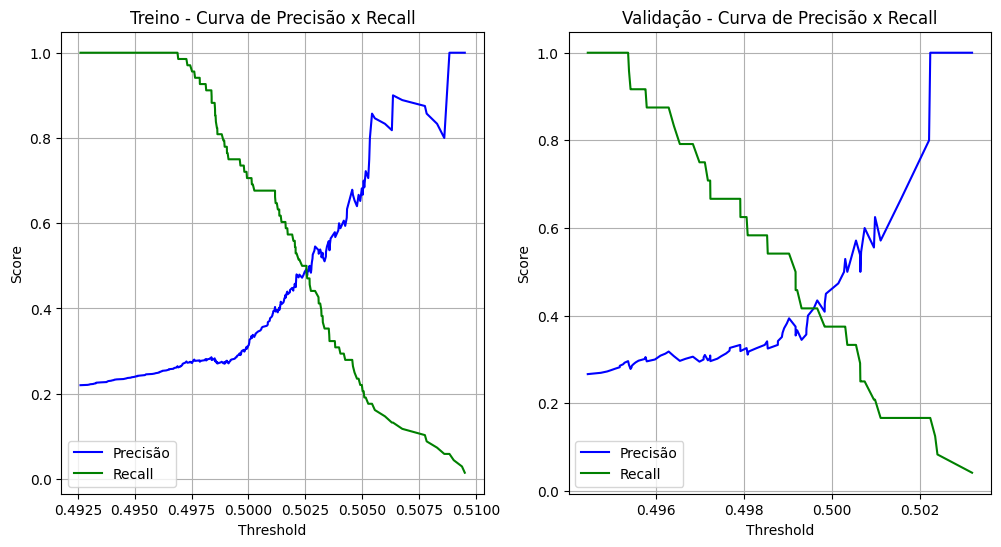

(np.float64(0.7208887233308844),
 np.float64(0.7772087611605435),
 np.float64(-0.05632003782965911),
 np.float64(0.5361929889046746),
 np.float64(0.5636161825150666),
 np.float64(0.3320316635622494),
 np.float64(0.4281686743997896))

In [276]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='liblinear', max_iter=5000,random_state=42, class_weight=class_weight, C=0.0001, penalty='l2')

pipeline_rl = Pipeline([
    ('scaler', StandardScaler()), 
    ('modelo', modelo_rl)
])

pipeline_rl.fit(X_train_subset, y_train)
tr.comparar_auc_conjuntos(pipeline_rl, X_train_subset, y_train, X_validacao_subset, y_validacao)

In [277]:
pd.DataFrame({'feature': X_train_subset.columns
              , 'coef': modelo_rl.coef_[0]
              , 'coef_abs': np.abs(modelo_rl.coef_[0])              
              }).sort_values(by='coef_abs', ascending=False).head(20)

,feature,coef,coef_abs
1,atr_pct_ultimo,0.005204,0.005204
2,close_norm_ultimo,-0.004952,0.004952
4,regime_tendencia,-0.004278,0.004278
3,cmf_ultimo,-0.003046,0.003046
0,alpha_papel_vs_ibov_mean,0.002561,0.002561
5,regime_volatilidade,-0.002053,0.002053
6,retorno_acumulado_norm,0.001981,0.001981


Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 313583328458643828).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/313583328458643828
MLflow Run ID: 42add6faf2bd441493a13b786bedf505 para ITUB4.SA_6dias_x_0.05val_10dias_alvo
AUC no treino: 0.740
AUC na validação: 0.644

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.721
  Precisão média (em 246 janelas com previsão positiva): 0.321
  Recall médio: 0.559

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 32.14%
  Recall Médio Esperado: 55.94%
  Janelas Usadas para Precisão: 246.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 59 janelas com previsão positiva): 0.247
Recall médio: 0.324
Sinais de compra presentes na vallidação: 24.0
Sinais de compra previstos na validação: 19


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Modelo ITUB4.SA_6dias_x_0.05val_10dias_alvo salvo na run 42add6faf2bd441493a13b786bedf505


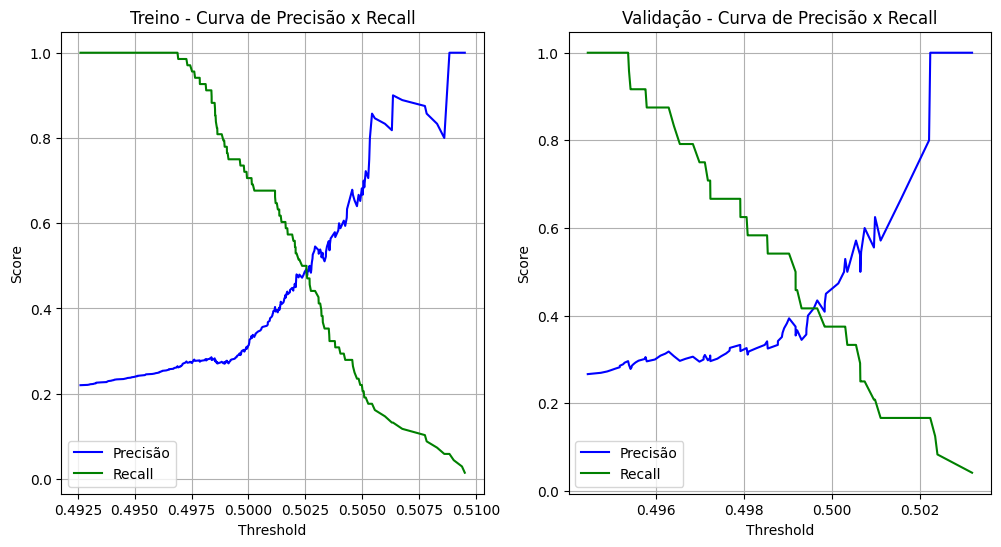

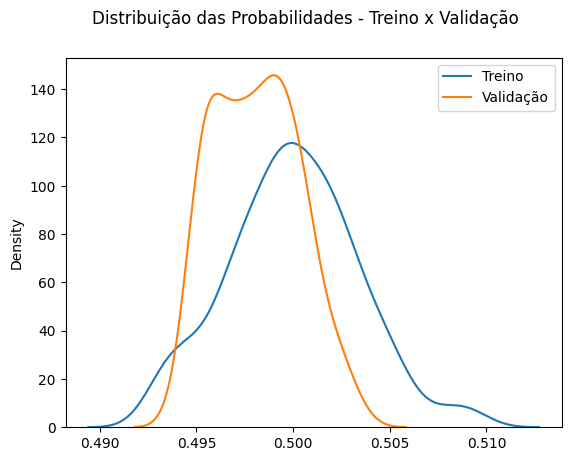

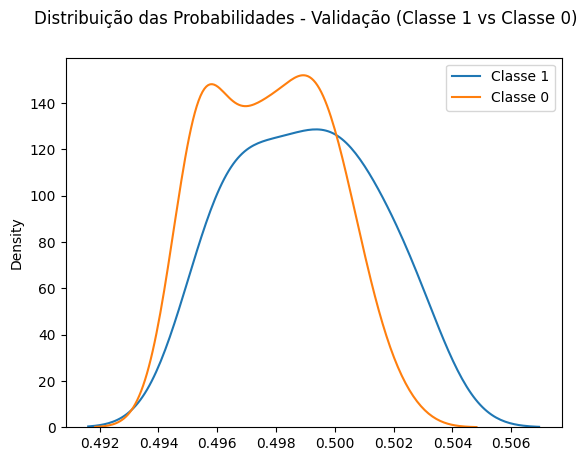

In [278]:
recall_minimo = None
precisao_minima = None
threshold_fixo = 0.5
resultado = tr.avaliar_e_logar_modelo(pipeline_rl, papel, X_train_subset, y_train, X_validacao_subset, y_validacao, dias_janela_x=dias_entrada, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima, threshold_fixo=threshold_fixo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [279]:
print(X_train.columns.tolist())

['close_norm_mean', 'close_norm_std', 'close_norm_max', 'close_norm_min', 'close_norm_trend', 'close_norm_ultimo', 'retorno_acumulado_ultimos_5_dias', 'retorno_mean', 'retorno_std', 'dias_alta_pct', 'dias_queda_pct', 'retorno_medio_pos', 'retorno_medio_neg', 'volume_mean', 'volume_std', 'volume_trend', 'volume_ult_vs_mean', 'correl_retorno_volume', 'rsi_mean', 'rsi_std', 'rsi_ultimo', 'rsi_trend', 'macd_mean', 'macd_std', 'macd_ultimo', 'macd_trend', 'macd_signal_mean', 'macd_signal_std', 'macd_signal_ultimo', 'macd_signal_trend', 'macd_hist_mean', 'macd_hist_std', 'macd_hist_ultimo', 'macd_hist_trend', 'obv_mean', 'obv_std', 'obv_ultimo', 'obv_trend', 'cmf_mean', 'cmf_std', 'cmf_ultimo', 'cmf_trend', 'atr_pct_mean', 'atr_pct_std', 'atr_pct_ultimo', 'atr_pct_trend', 'adx_ultimo', 'adx_trend', 'tendencia_forte_adx25', 'bbands_largura_pct_ultimo', 'bbands_largura_pct_trend', 'bbands_posicao_pct_ultimo', 'bbands_exaustao_compra', 'bbands_exaustao_venda', 'adc_close_norm_trend_BBAS3', 'adc

# Definição de threshold com janela rolante + retreinamento

## Definição de features com grupos incrementais

In [280]:
GRUPOS_CANDIDATOS = {
    'heroicas': [
        'close_norm_ultimo', 'retorno_acumulado_norm', 'atr_pct_ultimo',
        'cmf_ultimo', 'alpha_papel_vs_ibov_mean'
    ],
    'dinamica_momentum': [
        'rsi_trend', 'macd_hist_trend'
    ],
    'dinamica_volume': [
        'volume_trend', 'correl_retorno_volume', 'obv_trend'
    ],
    'contexto_mercado': [
        'adx_ultimo', 'bbands_largura_pct_ultimo', 'ibov_trend', 'dolar_trend'
    ],
    'pares': [
        'adc_close_norm_mean_geral_ultimo', 'close_norm_vs_adc_norm_mean_geral'
    ]
    , 'regimes': [
        'regime_tendencia', 'regime_volatilidade'
    ]
}

# 3. Definir o modelo template (simples e regularizado)
modelo_base_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        solver='liblinear', penalty='l2', C=0.1, random_state=42, class_weight='balanced'
    ))
])

#4. Executar a busca
#Supondo que X_train e y_train estão definidos
features_campeas_finais, df_resultados_busca = encontrar_melhor_conjunto_features_incremental(
    X_train, y_train,
    GRUPOS_CANDIDATOS,
    modelo_base_pipeline,
    tamanho_janela_treino_wf=252,
    tamanho_janela_validacao_wf=21    
) 

features_campeas_finais


--- Iniciando Busca Incremental pelo Melhor Conjunto de Features (Janela Rolante) ---

>>> Testando adição do grupo: 'baseline'
  Conjunto com 0 features. F1-médio (WF Rolante): 0.0000
  MELHORA! Score atual (0.0000) > Melhor anterior (-1.0000). Mantendo o grupo.

>>> Testando adição do grupo: 'heroicas'
  Conjunto com 5 features. F1-médio (WF Rolante): 0.6222
  MELHORA! Score atual (0.6222) > Melhor anterior (0.0000). Mantendo o grupo.

>>> Testando adição do grupo: 'dinamica_momentum'
  Conjunto com 7 features. F1-médio (WF Rolante): 0.4000
  Sem melhora. Score atual (0.4000) <= Melhor anterior (0.6222). Descartando o grupo.

>>> Testando adição do grupo: 'dinamica_volume'
  Conjunto com 8 features. F1-médio (WF Rolante): 0.6520
  MELHORA! Score atual (0.6520) > Melhor anterior (0.6222). Mantendo o grupo.

>>> Testando adição do grupo: 'contexto_mercado'
  Conjunto com 12 features. F1-médio (WF Rolante): 0.5132
  Sem melhora. Score atual (0.5132) <= Melhor anterior (0.6520). Descart

['alpha_papel_vs_ibov_mean',
 'atr_pct_ultimo',
 'close_norm_ultimo',
 'cmf_ultimo',
 'correl_retorno_volume',
 'obv_trend',
 'retorno_acumulado_norm',
 'volume_trend']

In [281]:
X_train_subset = X_train[features_campeas_finais].copy()
X_validacao_subset = X_validacao[features_campeas_finais].copy()

## Otimização de hiperparâmetros. Treina 6m, valida 1m

In [282]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score
from sklearn.pipeline import Pipeline # Assumindo que você pode usar pipeline
from sklearn.preprocessing import StandardScaler # Assumindo que pode usar pipeline

def gerador_de_janela_rolante_cv(n_amostras, tamanho_janela_treino, tamanho_janela_validacao, passo_wf):
    """
    (Gerador Auxiliar)
    Cria um gerador de índices de treino/validação para validação cruzada
    com janela rolante de tamanho fixo.
    """
    inicio_janela_treino = 0
    while True:
        fim_janela_treino = inicio_janela_treino + tamanho_janela_treino
        inicio_janela_validacao = fim_janela_treino
        fim_janela_validacao = inicio_janela_validacao + tamanho_janela_validacao
        
        if fim_janela_validacao > n_amostras:
            break
            
        indices_treino = np.arange(inicio_janela_treino, fim_janela_treino)
        indices_validacao = np.arange(inicio_janela_validacao, fim_janela_validacao)
        
        yield indices_treino, indices_validacao
        
        inicio_janela_treino += passo_wf


def otimizar_hiperparametros_logreg_com_janela_rolante(
        X_super_treino, y_super_treino,
        tamanho_janela_treino_wf: int = 126, # Aprox. 6 meses
        tamanho_janela_validacao_wf: int = 21,  # Aprox. 1 mês
        passo_wf: int = 21, # Desliza 1 mês
        pipeline_template=None
    ):
    """
    Encontra os melhores hiperparâmetros para a Regressão Logística usando
    GridSearchCV com uma validação cruzada de JANELA ROLANTE personalizada.
    """
    print(f"\n--- Iniciando Otimização de Hiperparâmetros com Janela Rolante ---")
    print(f"Janela de Treino: {tamanho_janela_treino_wf}, Janela de Validação: {tamanho_janela_validacao_wf}, Passo: {passo_wf}")
    
    # 1. Criar o gerador de validação cruzada personalizado
    cv_janela_rolante = gerador_de_janela_rolante_cv(
        n_amostras=len(X_super_treino),
        tamanho_janela_treino=tamanho_janela_treino_wf,
        tamanho_janela_validacao=tamanho_janela_validacao_wf,
        passo_wf=passo_wf
    )

    # 2. Definir o modelo base (template)
    if pipeline_template is None:
        # É altamente recomendado usar um pipeline para escalar os dados em cada fold
        pipeline_template = Pipeline([
            ('scaler', StandardScaler()),
            ('modelo', LogisticRegression(random_state=42, max_iter=2000, class_weight='balanced'))
        ])
    
    # 3. Definir o "grid" de parâmetros
    param_grid = [
        {
            'modelo__penalty': ['l1'],
            'modelo__solver': ['liblinear', 'saga'],
            'modelo__C': np.logspace(-3, 1, 5) # Ex: [0.001, 0.01, 0.1, 1, 10]
        },
        {
            'modelo__penalty': ['l2'],
            'modelo__solver': ['liblinear', 'lbfgs', 'saga'],
            'modelo__C': np.logspace(-3, 1, 5)
        }
    ]

    # 4. Definir a métrica de scoring
    scorer = make_scorer(f1_score) # Mantendo F1-score como no seu código

    # 5. Configurar e executar o GridSearchCV
    grid_search = GridSearchCV(
        estimator=pipeline_template, # Usa o pipeline
        param_grid=param_grid,
        scoring=scorer,
        cv=cv_janela_rolante, # <<< USA O GERADOR DE JANELA ROLANTE PERSONALIZADO
        n_jobs=-1,
        verbose=1
    )

    # Limpar dados antes do fit para segurança
    X_limpo = X_super_treino.copy()
    y_limpo = y_super_treino.copy()
    X_limpo.replace([np.inf, -np.inf], np.nan, inplace=True)
    X_limpo.fillna(X_limpo.mean(), inplace=True) # Preencher NaNs

    grid_search.fit(X_limpo, y_limpo)

    print("\n--- Resultados da Otimização ---")
    print(f"Melhor Score (F1-médio na CV rolante): {grid_search.best_score_:.4f}")
    print("Melhores Parâmetros Encontrados:")
    print(grid_search.best_params_)

    # O grid_search.best_estimator_ já é o modelo (pipeline) treinado com os melhores parâmetros
    # em TODO o X_super_treino.
    return grid_search.best_estimator_

In [283]:
melhor_modelo_pipeline = otimizar_hiperparametros_logreg_com_janela_rolante(
        X_super_treino=X_train_subset,
        y_super_treino=y_train,
        tamanho_janela_treino_wf=252, # 1 ano
        tamanho_janela_validacao_wf=21,  # 1 mês
        passo_wf=21
    )
    
print("\nModelo final (pipeline) otimizado:", melhor_modelo_pipeline)


--- Iniciando Otimização de Hiperparâmetros com Janela Rolante ---
Janela de Treino: 252, Janela de Validação: 21, Passo: 21
Fitting 2 folds for each of 25 candidates, totalling 50 fits

--- Resultados da Otimização ---
Melhor Score (F1-médio na CV rolante): 0.7167
Melhores Parâmetros Encontrados:
{'modelo__C': np.float64(0.1), 'modelo__penalty': 'l1', 'modelo__solver': 'saga'}

Modelo final (pipeline) otimizado: Pipeline(steps=[('scaler', StandardScaler()),
                ('modelo',
                 LogisticRegression(C=np.float64(0.1), class_weight='balanced',
                                    max_iter=2000, penalty='l1',
                                    random_state=42, solver='saga'))])


In [284]:
import pandas as pd
import numpy as np
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score
from sklearn.ensemble import RandomForestClassifier # Exemplo, pode ser qualquer modelo

def otimizar_threshold_com_walk_forward_rolante(
        X_super_train: pd.DataFrame,
        y_super_train: pd.Series,
        modelo_nao_treinado_factory, # Função que retorna uma nova instância do modelo
        tamanho_janela_treino: int, # Ex: 126 (aprox. 6 meses de dias úteis)
        tamanho_janela_validacao: int, # Ex: 21 (aprox. 1 mês de dias úteis)
        passo_wf: int, # Ex: 21 (desliza 1 mês a cada iteração)
        recall_minimo_desejado: float,
        thresholds_para_testar = np.arange(0.40, 0.61, 0.01) # Um range razoável para começar
    ):
    """
    Realiza validação walk-forward com janela de treino ROLANTE e retreinamento,
    para encontrar o threshold de decisão ideal dentro do "super" conjunto de treino.

    Args:
        X_super_train: DataFrame completo de features para o "super" treino.
        y_super_train: Series completa de alvos para o "super" treino.
        modelo_nao_treinado_factory: Função que retorna uma instância NÃO TREINADA do modelo.
                                     Ex: lambda: RandomForestClassifier(n_estimators=100)
        tamanho_janela_treino: Número de amostras na janela de treino rolante.
        tamanho_janela_validacao: Número de amostras na janela de validação interna.
        passo_wf: Número de amostras para deslizar as janelas.
        recall_minimo_desejado: O recall mínimo para filtrar thresholds candidatos.
        thresholds_para_testar: Array de thresholds de probabilidade a serem testados.

    Returns:
        dict: Contendo 'threshold_ideal', 'precisao_media_otima', 'recall_medio_otimo',
              e um DataFrame com os resultados agregados para cada threshold.
    """
    print(f"\n--- Iniciando Otimização de Threshold com Walk-Forward Rolante ---")
    print(f"Janela de Treino: {tamanho_janela_treino} amostras, Janela de Validação: {tamanho_janela_validacao}, Passo: {passo_wf}")

    # Dicionário para acumular métricas para cada threshold em todos os folds
    resultados_agregados = {
        thresh: {'precisions': [], 'recalls': []} for thresh in thresholds_para_testar
    }
    
    n_total_amostras = len(X_super_train)
    num_janelas_executadas = 0

    # O loop desliza o INÍCIO da janela de treino
    for inicio_treino_idx in range(0, n_total_amostras, passo_wf):
        fim_treino_idx = inicio_treino_idx + tamanho_janela_treino
        inicio_validacao_idx = fim_treino_idx
        fim_validacao_idx = inicio_validacao_idx + tamanho_janela_validacao

        # Se a janela de validação ultrapassar o final dos dados, paramos
        if fim_validacao_idx > n_total_amostras:
            break

        X_treino_janela = X_super_train.iloc[inicio_treino_idx : fim_treino_idx]
        y_treino_janela = y_super_train.iloc[inicio_treino_idx : fim_treino_idx]
        X_validacao_janela = X_super_train.iloc[inicio_validacao_idx : fim_validacao_idx]
        y_validacao_janela = y_super_train.iloc[inicio_validacao_idx : fim_validacao_idx]

        if X_treino_janela.empty or X_validacao_janela.empty or y_treino_janela.sum() == 0:
            print(f"  AVISO: Janela {num_janelas_executadas + 1} pulada (dados de treino/validação vazios ou sem eventos positivos no treino).")
            continue
            
        num_janelas_executadas += 1
        print(f"  Walk-Forward Janela {num_janelas_executadas}: Treinando com {len(X_treino_janela)}, Validando com {len(X_validacao_janela)}...")

        # 1. Instanciar e RETREINAR o modelo para esta janela de treino
        modelo_janela = modelo_nao_treinado_factory()
        try:
            modelo_janela.fit(X_treino_janela.values, y_treino_janela.values) # Usando .values por compatibilidade
        except Exception as e_fit:
            print(f"    ERRO ao treinar modelo na janela {num_janelas_executadas}: {e_fit}. Pulando esta janela.")
            continue

        # 2. Obter probabilidades na janela de validação
        try:
            probabilidades_val = modelo_janela.predict_proba(X_validacao_janela.values)[:, 1]
        except Exception as e_pred:
            print(f"    ERRO ao prever na janela {num_janelas_executadas}: {e_pred}. Pulando.")
            continue

        # 3. Calcular métricas para cada threshold e acumular
        for p_thresh in thresholds_para_testar:
            predicoes_binarias = (probabilidades_val >= p_thresh).astype(int)
            
            precision = precision_score(y_validacao_janela.values, predicoes_binarias, zero_division=0)
            recall = recall_score(y_validacao_janela.values, predicoes_binarias, zero_division=0)

            resultados_agregados[p_thresh]['precisions'].append(precision)
            resultados_agregados[p_thresh]['recalls'].append(recall)
                
    if num_janelas_executadas == 0:
        print("AVISO: Nenhuma janela de walk-forward foi executada. Verifique os tamanhos das janelas e dados.")
        return {'threshold_ideal': None, 'precisao_media_otima': None, 'recall_medio_otimo': None,
                'df_resultados_agregados': pd.DataFrame()}

    # Calcular médias e selecionar threshold ideal
    df_res_list = []
    for p_thresh, metrics_list in resultados_agregados.items():
        if metrics_list['precisions']: # Apenas se houve cálculos para este threshold
            avg_precision = np.mean(metrics_list['precisions'])
            avg_recall = np.mean(metrics_list['recalls'])
            std_precision = np.std(metrics_list['precisions'])

            df_res_list.append({
                'threshold': p_thresh,
                'precisao_media': avg_precision,
                'recall_medio': avg_recall,
                'precisao_std': std_precision
            })
    
    df_resultados_agregados = pd.DataFrame(df_res_list)
    
    print("\n--- Resultados Agregados por Threshold (Walk-Forward no Super Treino) ---")
    if not df_resultados_agregados.empty:
        print(df_resultados_agregados.round(3))
    else:
        print("Nenhum resultado agregado foi calculado.")
        return {'threshold_ideal': None, 'precisao_media_otima': None, 'recall_medio_otimo': None,
                'df_resultados_agregados': pd.DataFrame()}

    # Selecionar o melhor threshold com base no critério
    df_candidatos = df_resultados_agregados[df_resultados_agregados['recall_medio'] >= recall_minimo_desejado].copy()

    threshold_ideal_final = None
    precisao_otima_final = None
    recall_otimo_final = None

    if not df_candidatos.empty:
        # Priorizar maior precisão, depois menor desvio padrão da precisão (para estabilidade)
        df_candidatos.sort_values(by=['precisao_media', 'precisao_std'], ascending=[False, True], inplace=True)
        melhor_candidato = df_candidatos.iloc[0]
        threshold_ideal_final = melhor_candidato['threshold']
        precisao_otima_final = melhor_candidato['precisao_media']
        recall_otimo_final = melhor_candidato['recall_medio']
        print(f"\n--- Threshold Ideal Selecionado (do Super Treino WF) ---")
        print(f"  Threshold: {threshold_ideal_final:.3f}")
        print(f"  Precisão Média Esperada: {precisao_otima_final:.2%}")
        print(f"  Recall Médio Esperado: {recall_otimo_final:.2%}")
    else:
        print(f"\nAVISO: Nenhum threshold atendeu ao recall mínimo de {recall_minimo_desejado:.2%} no walk-forward.")

    return {
        'threshold_ideal': threshold_ideal_final,
        'precisao_media_otima': precisao_otima_final,
        'recall_medio_otimo': recall_otimo_final,
        'df_resultados_agregados': df_resultados_agregados
    }


In [285]:
X_train_subset.columns.tolist()

['alpha_papel_vs_ibov_mean',
 'atr_pct_ultimo',
 'close_norm_ultimo',
 'cmf_ultimo',
 'correl_retorno_volume',
 'obv_trend',
 'retorno_acumulado_norm',
 'volume_trend']

In [290]:
n_dias_super_treino = 510

# Parâmetros para o Walk-Forward de Otimização
tamanho_janela_treino_ex = 252 # Aprox. 6 meses
tamanho_janela_val_ex = 21      # Aprox. 1 mês
passo_wf_ex = 21                # Desliza 1 mês a cada iteração
recall_minimo_ex = 0.05         # Exige pelo menos 15% de recall

# Fábrica de modelo: uma função lambda que retorna uma nova instância do seu modelo
# Use os hiperparâmetros que você já otimizou com GridSearchCV
def criar_meu_modelo_otimizado():
    # Exemplo com RandomForest
    modelo_rl = LogisticRegression(solver='saga', max_iter=5000,random_state=42, class_weight=class_weight, C=0.1, penalty='l1')

    pipeline_rl = Pipeline([
        ('scaler', StandardScaler()), 
        ('modelo', modelo_rl)
    ])

    return pipeline_rl

# Executar a otimização
resultados_otimizacao = otimizar_threshold_com_walk_forward_rolante(
    X_super_train=X_train_subset,
    y_super_train=y_train,
    modelo_nao_treinado_factory=criar_meu_modelo_otimizado,
    tamanho_janela_treino=tamanho_janela_treino_ex,
    tamanho_janela_validacao=tamanho_janela_val_ex,
    passo_wf=passo_wf_ex,
    recall_minimo_desejado=recall_minimo_ex,
    thresholds_para_testar=np.arange(0.45, 0.56, 0.01)
)

threshold_final_para_producao = resultados_otimizacao['threshold_ideal']
print(f"\n\nO threshold final a ser usado em produção é: {threshold_final_para_producao}")


--- Iniciando Otimização de Threshold com Walk-Forward Rolante ---
Janela de Treino: 252 amostras, Janela de Validação: 21, Passo: 21
  Walk-Forward Janela 1: Treinando com 252, Validando com 21...
  Walk-Forward Janela 2: Treinando com 252, Validando com 21...

--- Resultados Agregados por Threshold (Walk-Forward no Super Treino) ---
    threshold  precisao_media  recall_medio  precisao_std
0        0.45           0.399         1.000         0.189
1        0.46           0.424         1.000         0.201
2        0.47           0.451         1.000         0.216
3        0.48           0.476         1.000         0.190
4        0.49           0.524         1.000         0.190
5        0.50           0.607         0.875         0.107
6        0.51           0.607         0.750         0.107
7        0.52           0.750         0.750         0.083
8        0.53           0.750         0.625         0.250
9        0.54           1.000         0.625         0.000
10       0.55           

In [287]:
X_train_subset.columns.tolist()

['alpha_papel_vs_ibov_mean',
 'atr_pct_ultimo',
 'close_norm_ultimo',
 'cmf_ultimo',
 'correl_retorno_volume',
 'obv_trend',
 'retorno_acumulado_norm',
 'volume_trend']

### Validação Hold-out com janelas rolantes e re-treinamento

In [288]:
import pandas as pd
import numpy as np
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt

def backtest_final_walk_forward(
        modelo_template, # Um modelo NÃO treinado com os hiperparâmetros já otimizados
        X_super_treino: pd.DataFrame,
        y_super_treino: pd.Series,
        X_validacao_final: pd.DataFrame,
        y_validacao_final: pd.Series,
        tamanho_janela_treino: int, # Ex: 252 (aprox. 1 ano)
        passo_wf: int = 21 # Ex: 21 (retreina a cada 1 mês)
    ) -> dict:
    """
    Realiza um backtest final em um conjunto de validação (hold-out) usando
    uma estratégia de walk-forward com janela rolante e retreinamento.

    Args:
        modelo_template: Uma instância NÃO TREINADA do modelo final com hiperparâmetros otimizados.
        X_super_treino: O conjunto completo de features de treino.
        y_super_treino: Os alvos completos de treino.
        X_validacao_final: O conjunto de features de validação hold-out.
        y_validacao_final: Os alvos de validação hold-out.
        tamanho_janela_treino (int): Tamanho da janela de treino rolante.
        passo_wf (int): O número de amostras para avançar a cada retreinamento.

    Returns:
        dict: Um dicionário contendo as previsões de probabilidade, os alvos reais,
              e um DataFrame com as métricas calculadas em todo o período de validação.
    """
    print("\n--- Iniciando Backtest Final com Walk-Forward e Retreinamento ---")
    print(f"Janela de Treino: {tamanho_janela_treino}, Passo de Retreinamento: {passo_wf}")
    
    # Combinar os dados de treino e validação para facilitar o fatiamento
    X_completo = pd.concat([X_super_treino, X_validacao_final])
    y_completo = pd.concat([y_super_treino, y_validacao_final])

    lista_probas_out_of_sample = []
    lista_y_reais_out_of_sample = []
    indices_out_of_sample = []

    # O loop vai iterar sobre o conjunto de validação, com base no passo_wf
    n_validacao = len(X_validacao_final)
    offset_inicio_treino = len(X_super_treino) - tamanho_janela_treino

    for i in range(0, n_validacao, passo_wf):
        
        # --- Definir Janelas ---
        # Janela de treino: `tamanho_janela_treino` amostras terminando ANTES do início da janela de teste
        inicio_treino_idx = offset_inicio_treino + i
        fim_treino_idx = inicio_treino_idx + tamanho_janela_treino
        
        # Janela de teste: `passo_wf` amostras (ou menos, no último passo)
        inicio_teste_idx = fim_treino_idx
        fim_teste_idx = min(inicio_teste_idx + passo_wf, len(X_completo))

        if inicio_teste_idx >= fim_teste_idx: # Se não houver mais dados para testar
            break

        X_treino_janela = X_completo.iloc[inicio_treino_idx : fim_treino_idx]
        y_treino_janela = y_completo.iloc[inicio_treino_idx : fim_treino_idx]
        X_teste_janela = X_completo.iloc[inicio_teste_idx : fim_teste_idx]
        y_teste_janela = y_completo.iloc[inicio_teste_idx : fim_teste_idx]

        print(f"  Backtest Passo {i//passo_wf + 1}: Treinando com {len(X_treino_janela)} amostras [{X_treino_janela.index.min()} a {X_treino_janela.index.max()}], "
              f"Prevendo {len(X_teste_janela)} amostras [{X_teste_janela.index.min()} a {X_teste_janela.index.max()}]...")

        # --- Treinar e Prever ---
        modelo = clone(modelo_template)
        try:
            modelo.fit(X_treino_janela, y_treino_janela)
            probas_janela = modelo.predict_proba(X_teste_janela)[:, 1]
            
            # Armazenar resultados
            lista_probas_out_of_sample.extend(probas_janela)
            lista_y_reais_out_of_sample.extend(y_teste_janela.values)
            indices_out_of_sample.extend(y_teste_janela.index)
            
        except Exception as e:
            print(f"    ERRO no Passo {i//passo_wf + 1}: {e}. Pulando este passo.")
            # Preencher com previsões "neutras" (0.5) para manter o alinhamento
            lista_probas_out_of_sample.extend([0.5] * len(y_teste_janela))
            lista_y_reais_out_of_sample.extend(y_teste_janela.values)
            indices_out_of_sample.extend(y_teste_janela.index)

    # --- Consolidar e Avaliar Resultados Finais ---
    if not lista_probas_out_of_sample:
        print("AVISO: Nenhum resultado de backtest foi gerado.")
        return None

    probas_finais_val = pd.Series(lista_probas_out_of_sample, index=indices_out_of_sample)
    y_reais_finais_val = pd.Series(lista_y_reais_out_of_sample, index=indices_out_of_sample)

    # Calcular métricas em diferentes thresholds para análise
    resultados_thresholds = []
    for threshold in np.arange(0.40, 0.61, 0.01):
        y_pred = (probas_finais_val >= threshold).astype(int)
        
        prec = precision_score(y_reais_finais_val, y_pred, zero_division=0)
        rec = recall_score(y_reais_finais_val, y_pred, zero_division=0)
        f1 = f1_score(y_reais_finais_val, y_pred, zero_division=0)
        num_sinais = y_pred.sum()

        resultados_thresholds.append({
            'threshold': threshold,
            'precisao': prec,
            'recall': rec,
            'f1_score': f1,
            'num_sinais': num_sinais
        })
    
    df_metricas_finais = pd.DataFrame(resultados_thresholds)
    
    print("\n--- Resultados Finais do Backtest no Hold-Out ---")
    print(df_metricas_finais.round(3).to_string())
    
    return {
        'probas_validacao': probas_finais_val,
        'y_reais_validacao': y_reais_finais_val,
        'metricas_por_threshold': df_metricas_finais
    }


--- Iniciando Backtest Final com Walk-Forward e Retreinamento ---
Janela de Treino: 252, Passo de Retreinamento: 21
  Backtest Passo 1: Treinando com 252 amostras [2024-04-19 a 2025-04-23], Prevendo 21 amostras [2025-04-24 a 2025-05-23]...
  Backtest Passo 2: Treinando com 252 amostras [2024-05-21 a 2025-05-23], Prevendo 21 amostras [2025-05-26 a 2025-06-24]...
  Backtest Passo 3: Treinando com 252 amostras [2024-06-20 a 2025-06-24], Prevendo 21 amostras [2025-06-25 a 2025-07-23]...
  Backtest Passo 4: Treinando com 252 amostras [2024-07-19 a 2025-07-23], Prevendo 21 amostras [2025-07-24 a 2025-08-21]...
  Backtest Passo 5: Treinando com 252 amostras [2024-08-19 a 2025-08-21], Prevendo 6 amostras [2025-08-22 a 2025-08-29]...

--- Resultados Finais do Backtest no Hold-Out ---
    threshold  precisao  recall  f1_score  num_sinais
0        0.40     0.185   0.208     0.196          27
1        0.41     0.174   0.167     0.170          23
2        0.42     0.136   0.125     0.130          

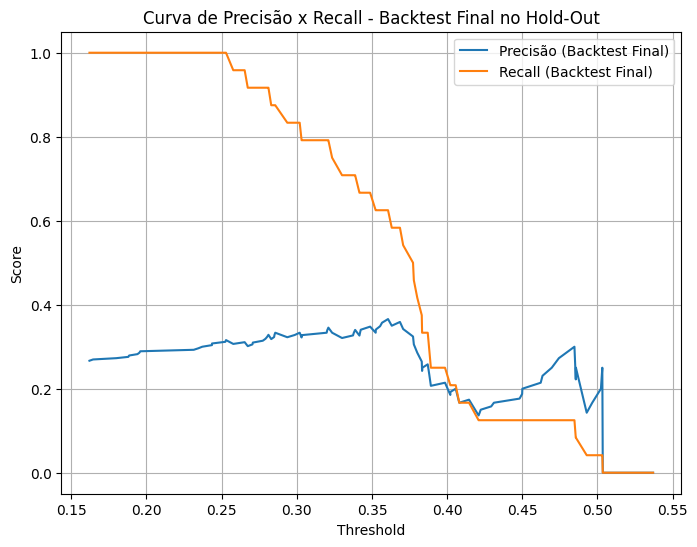

In [291]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Definir o modelo "campeão" (com hiperparâmetros já otimizados)
modelo_final_template = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        solver='saga', penalty='l1', C=0.1, random_state=42, class_weight='balanced'
    ))
])

# Executar o backtest
resultados_backtest = backtest_final_walk_forward(
    modelo_template=modelo_final_template,
    X_super_treino=X_train_subset,
    y_super_treino=y_train,
    X_validacao_final=X_validacao_subset,
    y_validacao_final=y_validacao,
    tamanho_janela_treino=252, # 1 ano
    passo_wf=21 # Retreina a cada mês
)

# Plotar as curvas de P-R para o resultado do backtest
if resultados_backtest:
    from sklearn.metrics import precision_recall_curve
    probas_val = resultados_backtest['probas_validacao']
    y_val = resultados_backtest['y_reais_validacao']
    
    precisions, recalls, thresholds = precision_recall_curve(y_val, probas_val)
    
    plt.figure(figsize=(8, 6))
    plt.plot(thresholds, precisions[:-1], label='Precisão (Backtest Final)')
    plt.plot(thresholds, recalls[:-1], label='Recall (Backtest Final)')
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title("Curva de Precisão x Recall - Backtest Final no Hold-Out")
    plt.grid(True)
    plt.legend()
    plt.show()